# Numpyro

In [10]:
import os
#os.environ["XLA_FLAGS"] = "--xla_force_host_platform_device_count=4"

import numpyro
numpyro.set_host_device_count(4)
import jax
import jax.numpy as jnp
import jax.scipy as jscipy
import jax.random as jrand 

import numpyro.distributions as dist
from jax import vmap
from jax import jit
from jax import lax

import h5py
import json
import seaborn as sns
import numpy as np

from numpyro.infer import MCMC, NUTS, init_to_value

import arviz as az

import matplotlib.pyplot as plt

In [11]:
#constants
k_DM = (2.41*1e-4)**(-1) #pc^-1 * cm^3 * GHz^2 * s

## Model

In [12]:
def setup_model(constants_dict,freqs_channels,times):
    """
        Setting up the necessary constants for the model itself. The model will be written as a closure within the setup method.
        
        constants_dict: dict of each constant in the model
        freq_channels: array of frequency channels in the data
        times: array of time bins in the data
    """


    ### We are setting up constant values here
    det_response = jnp.float32(1) # TO-DO: WILL BE FUNCTION LATER !!!! Maybe also convolution is involved if frequencies are not independent between channels
    freq_channels_ref = jnp.float32(constants_dict["freq_channels_ref"]) # fixed reference / pivot EM frequency nu_r, set approximately equal to frequency of peak emission for a pulse with Gaussian-like SED in the dynamic spectrum element D_kn
    # tau_ref = jnp.float32(constants_dict["tau_ref"]) # fixed scatter broadening timescale at freq_ref; if 0, no scatter is put in the model
    delta = jnp.float32(constants_dict["delta"])
    k_DM = jnp.float32(constants_dict["k_DM"])# dispersion constant, (2.41*1e-4)**(-1) #pc^-1 * cm^3 * GHz^2 * s
    epsilon = jnp.float32(constants_dict["epsilon"]) # Exponent of frequency dependence for pulse dispersion - for now it seems the model only actually allows this to be a constant -2, due to units.
    normalized_freqs_channels = freqs_channels/freq_channels_ref # nu_k / nu_r
    log_normalized_freqs_channels = jnp.log(normalized_freqs_channels)

    ## Defining things related to Fourier domain
    L = times[0].shape[0]
    dt = times[0][1] - times[0][0]
    fourier_freqs = jnp.fft.rfftfreq(L, d=dt,dtype=jnp.float32)[None, :]
    
    def single_pulse_model(params_dict):
            """
                Model of a single pulse, which will be summed in the forward model for multi-pulse signals.
                
                params_dict: dict of each parameter of the pulse
                freqs: array of frequency bins in the data
                times: array of time bins in the data
            """
        
            # frequency array nu_k
            # shape of (nfreq,1), units of MHz, these are the rows of the model matrix
            # freqs = jnp.asarray(freq_array, dtype=jnp.float32)[:, None]
            
            # time array t_n
            # shape of (1,ntime), units of seconds, these are the columns of the model matrix
            # times = jnp.asarray(time_array, dtype=jnp.float32)[None, :]
        
            #params
            alpha = jnp.float32(params_dict["alpha"]) # Base-10 exponent of amplitude for burst componnent
            gamma = jnp.float32(params_dict["gamma"]) # Spectral index for burst component
            beta = jnp.float32(params_dict["beta"]) # Spectral running for burst component
            # delta = jnp.float32(params_dict["delta"]) # Exponent of frequency dependence for scatter-broadening
            mean_arrival_time = jnp.float32(params_dict["mean_arrival_time"]) # defined so that the pulse peaks at freq_ref at this time (before scatter or dispersion shifts at other frequencies)
            sigma = jnp.float32(params_dict["sigma"]) #width of gaussian in pulse, without scatter-broadening
            DM = jnp.float32(params_dict["DM"]) # dispersion measure, pc/cm^3
            tau_ref = jnp.float32(params_dict["tau_ref"]) # scatter broadening timescale at freq_ref, if 0 then no scatter is put in the model, s

            # model
            A = 10**alpha
        
            kappa = gamma + ( beta * log_normalized_freqs_channels ) #Running power law of SED
            F = (normalized_freqs_channels**kappa) * det_response
        
            mean_time_gaussian = mean_arrival_time + ( k_DM * DM * ( (freqs_channels**epsilon) - (freq_channels_ref**epsilon) ) ) #mean time in the gaussian model with no scatter broadening
            
            taus = tau_ref * (normalized_freqs_channels ** delta) # Timescale of scattering-broadening at nu_k

            ### TO-DO : REMOVE THE FACTORS OUT FRONT IN T, THEY RENORMALIZE JUST FOR COMPARISON WITH FITBURST
            T = jnp.sqrt(2*jnp.pi) * sigma * jnp.exp( - 2 * ( (jnp.pi**2) * (sigma**2) * (fourier_freqs)**2 ) - 2j * ( jnp.pi * fourier_freqs * mean_time_gaussian) ) / (1 + 2j * jnp.pi * fourier_freqs * taus)
        
            M = A * F *T
        
            return M

    return single_pulse_model

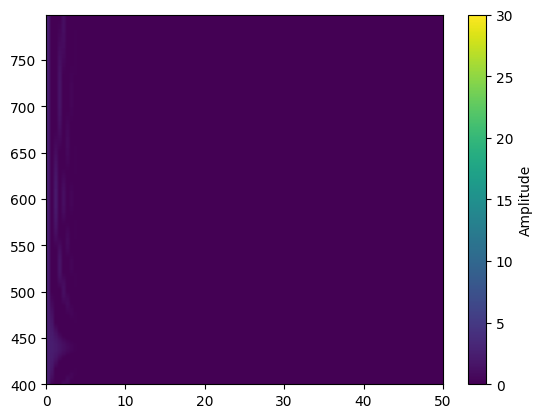

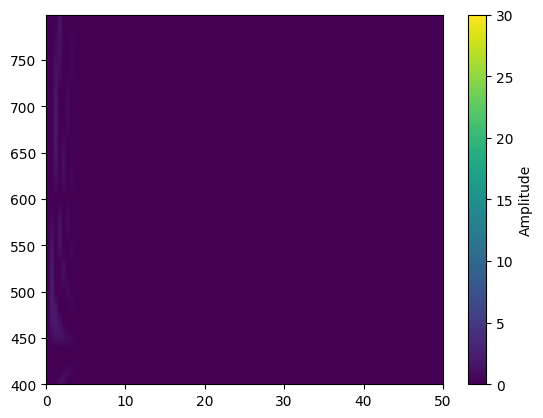

In [13]:
params_dict = {
    # Pulse and dispersion
    "DM": 100.0,           # pc/cm^3
    "tau_ref": 0 ,#0.000, # 0.015,      # s, scatter broadening at freq_ref
    "epsilon": -2.0,        # dispersion exponent
    
    # Temporal shape
    "sigma": 0.1,        # s, intrinsic width of pulse
    
    # Amplitude / spectrum
    "alpha": 1.0,          # log10 global amplitude
    "gamma": 0.0,         # spectral index for SED
    "beta": 0.0,           # running spectral index
    "delta": -4.0,          # scatter-frequency exponent
    "mean_arrival_time": 1.0,
    
}

# fixed / typical values
freq_channels_ref = 600.0
# gamma = 0.0
# beta = 0.0
delta = -4.0
epsilon = -2.0
tau_ref = 0.0 #numpyro.sample(f"tau_ref_{i}", dist.Uniform(0.0, 0.01))
k_DM = (2.41*1e-4)**(-1) #pc^-1 * cm^3 * GHz^2 * s

constants_dict = {
    "tau_ref": tau_ref,
    "freq_channels_ref": freq_channels_ref,
    "epsilon": epsilon,
    "k_DM": k_DM,
    "delta": -4.0
}

freq_array = jnp.arange(400,800,1, dtype=jnp.float32)[:, None]  # (nfreq,1), MHz
time_array = jnp.arange(1,3,0.01, dtype=jnp.float32)[None, :] # (1,ntime), s
single_pulse_model = setup_model(constants_dict, freq_array, time_array)

M = single_pulse_model(params_dict)

L = time_array[0].shape[0]
dt = time_array[0][1] - time_array[0][0]
fourier_freqs = jnp.fft.rfftfreq(L, d=dt,dtype=jnp.float32)[None, :]


plt.imshow(
    M.real,
    aspect='auto',
    origin='lower',
    extent=[fourier_freqs[0][0], fourier_freqs[0][-1], freq_array.T[0][0], freq_array.T[0][-1]],
    cmap = "viridis",
    vmin=0,
    vmax=30
)
plt.colorbar(label="Amplitude")

plt.figure()
plt.imshow(
    M.imag,
    aspect='auto',
    origin='lower',
    extent=[fourier_freqs[0][0], fourier_freqs[0][-1], freq_array.T[0][0], freq_array.T[0][-1]],
    cmap = "viridis",
    vmin=0,
    vmax=30
)
plt.colorbar(label="Amplitude")

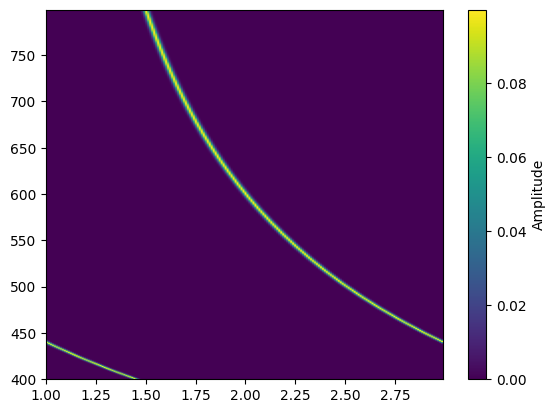

In [14]:
params_dict = {
    # Pulse and dispersion
    "DM": 100.0,           # pc/cm^3
    "tau_ref": 0 ,#0.000, # 0.015,      # s, scatter broadening at freq_ref
    "epsilon": -2.0,        # dispersion exponent
    
    # Temporal shape
    "sigma": 0.01,        # s, intrinsic width of pulse
    
    # Amplitude / spectrum
    "alpha": 1.0,          # log10 global amplitude
    "gamma": 0.0,         # spectral index for SED
    "beta": 0.0,           # running spectral index
    "delta": -4.0,          # scatter-frequency exponent
    "mean_arrival_time": 1.0,
    
}

# fixed / typical values
freq_channels_ref = 600.0
# gamma = 0.0
# beta = 0.0
delta = -4.0
epsilon = -2.0
tau_ref = 0.0 #numpyro.sample(f"tau_ref_{i}", dist.Uniform(0.0, 0.01))
k_DM = (2.41*1e-4)**(-1) #pc^-1 * cm^3 * GHz^2 * s

constants_dict = {
    "tau_ref": tau_ref,
    "freq_channels_ref": freq_channels_ref,
    "epsilon": epsilon,
    "k_DM": k_DM,
    "delta": -4.0
}

freq_array = jnp.arange(400,800,1, dtype=jnp.float32)[:, None]  # (nfreq,1), MHz
time_array = jnp.arange(1,3,0.01, dtype=jnp.float32)[None, :] # (1,ntime), s
single_pulse_model = setup_model(constants_dict, freq_array, time_array)

M = single_pulse_model(params_dict)

L = time_array[0].shape[0]
dt = time_array[0][1] - time_array[0][0]
fourier_freqs = jnp.fft.rfftfreq(L, d=dt,dtype=jnp.float32)[None, :]

# M *= jnp.exp(2j *jnp.pi * fourier_freqs * 1)

M_td = jnp.fft.irfft(M,axis=-1)


plt.imshow(
    M_td,
    aspect='auto',
    origin='lower',
    cmap = "viridis",
    extent=[time_array[0][0], time_array[0][-1], freq_array.T[0][0], freq_array.T[0][-1]],
)
plt.colorbar(label="Amplitude")


# plt.imshow(
#     M.real,
#     aspect='auto',
#     origin='lower',
#     extent=[fourier_freqs[0][0], fourier_freqs[0][-1], freq_array.T[0][0], freq_array.T[0][-1]],
#     cmap = "viridis",
#     vmin=0,
#     vmax=30
# )
# plt.colorbar(label="Amplitude")

# plt.figure()
# plt.imshow(
#     M.imag,
#     aspect='auto',
#     origin='lower',
#     extent=[fourier_freqs[0][0], fourier_freqs[0][-1], freq_array.T[0][0], freq_array.T[0][-1]],
#     cmap = "viridis",
#     vmin=0,
#     vmax=30
# )
# plt.colorbar(label="Amplitude")

In [15]:
### TO-DO!! Make these funcitons use lax.scan instead of for loop over M_total, and then make frb_forward_model a closure inside of numpyro_model and stack all of the parameters

def frb_forward_model(params_list, len_freq_channel_array, len_fourier_freq_array, single_pulse_method):
    """
    Forward model for multi-pulse FRB as sum of single pulses.

    Parameters
    ----------
    params_list : list of dict
        Each dict contains parameters for a single pulse (as in single_pulse_model).
    params_list : list of dict
        Each dict contains constants for a single pulse (as in single_pulse_model).
    len_freq_channel_array : int
        Number of frequency channels
    len_fourier_freq_array : int
        Number of Fourier frequency bins

    Returns
    -------
    M : array (nfreq, ntime)
        Dynamic spectrum of the summed pulses
    """
    M_total = jnp.zeros((len_freq_channel_array, len_fourier_freq_array))

    # Sum over pulses
    for params_dict in params_list:#(params_dict, constants_dict) in zip(params_list, constants_list):
        M_total += single_pulse_method(params_dict)

    return M_total

def sample_scaled_uniform(name, low, high):
    """
    Sample from Uniform(low, high) via a unit-scale base variable, so NUTS's
    dense mass matrix estimation operates on O(1) values regardless of the
    parameter's true physical scale.
    """
    u = numpyro.sample(f"{name}_base", dist.Uniform(0.0, 1.0))
    value = numpyro.deterministic(name, low + u * (high - low))
    return value

def numpyro_model(data, len_freq_channel_array, len_fourier_freq_array, single_pulse_method, sigma_noise, n_pulses):
    """
    Numpyro model for multi-pulse FRB.
    data: assumed to be FFTd before passed in
    sigma_noise: defined as sqrt(PSD)
    """

    params_list = []

    for i in range(n_pulses):

        ##### 
        # FAKE DATA PRIORS
        #####
        
        # # Priors for pulse i
        # #DM = numpyro.sample(f"DM_{i}", dist.Uniform(0, 500))
        # DM = numpyro.sample(f"DM_{i}", dist.Uniform(-100, 100))
        # #mean_arrival_time = numpyro.sample(f"t0_{i}", dist.Uniform(0.0, 2.0))
        # mean_arrival_time = numpyro.sample(f"t0_{i}", dist.Uniform(-10, 10))
        # sigma = numpyro.sample(f"sigma_{i}", dist.Uniform(0.005, 0.1))
        # alpha = numpyro.sample(f"alpha_{i}", dist.Uniform(0, 2.0))
        # tau_ref = 0 #numpyro.sample(f"tau_ref_{i}", dist.Uniform(0.0, 0.01))
        # gamma = numpyro.sample(f"gamma_{i}", dist.Uniform(-10, 10))
        # beta = numpyro.sample(f"beta_{i}", dist.Uniform(-1, 1))
        # delta = numpyro.sample(f"delta_{i}", dist.Uniform(-4.5, -3.5))
        # epsilon = numpyro.sample(f"epsilon_{i}", dist.Uniform(-2.1, -1.9))

        # # fixed / typical values
        # freq_ref = 600.0
        # # gamma = 0.0
        # # beta = 0.0
        # # delta = -4.0
        # # epsilon = -2.0
        # k_DM = (2.41*1e-4)**(-1) #pc^-1 * cm^3 * GHz^2 * s
        
        ##### 
        # REAL DATA PRIORS
        #####
        
        # Priors for pulse i
        #DM = numpyro.sample(f"DM_{i}", dist.Uniform(0, 500))
        DM = numpyro.sample(f"DM_{i}", dist.Uniform(-10, 10))
        #mean_arrival_time = numpyro.sample(f"t0_{i}", dist.Uniform(0.0, 2.0))
        mean_arrival_time = numpyro.sample(f"t0_{i}", dist.Uniform(-0.02+0.08, 0.02+0.08))
        sigma = numpyro.sample(f"sigma_{i}", dist.Uniform(0.1/1000, 10/1000))
        alpha = numpyro.sample(f"alpha_{i}", dist.Uniform(-2.0, 0.0))
        gamma = numpyro.sample(f"gamma_{i}", dist.Uniform(-20, 10))
        beta = numpyro.sample(f"beta_{i}", dist.Uniform(-20, 10))
        tau_ref = numpyro.sample(f"tau_ref_{i}", dist.Uniform(0, 0.1))
        #delta = numpyro.sample(f"delta_{i}", dist.Uniform(-4.5, -3.5))
        # epsilon = numpyro.sample(f"epsilon_{i}", dist.Uniform(-2.1, -1.9))

        # {"amplitude": [-1.6610962224298984], "arrival_time": [482488.48689058475], "burst_width": [0.0004128824360633611], 
        #  "dm": [848.8783200451409], "dm_index": [-2.0], "scattering_timescale": [0.01009891957302962], "scattering_index": [-4.0], 
        #  "spectral_index": [2.078152594885448], "spectral_running": [-7.62940918595922], "ref_freq": [400.1953125]}

        
        # # fixed / typical values
        # freq_ref = 600.0
        # # gamma = 0.0
        # # beta = 0.0
        # delta = -4.0
        # epsilon = -2.0
        # tau_ref = 0.0 #numpyro.sample(f"tau_ref_{i}", dist.Uniform(0.0, 0.01))
        # k_DM = (2.41*1e-4)**(-1) #pc^-1 * cm^3 * GHz^2 * s

        params_dict = {
            "DM": DM,
            "mean_arrival_time": mean_arrival_time,
            "sigma": sigma,
            "alpha": alpha,
            "gamma": gamma,
            "beta": beta,
            "tau_ref":tau_ref
        }

        # constants_dict = {
        #     "tau_ref": tau_ref,
        #     "freq_ref": freq_ref,
        #     "epsilon": epsilon,
        #     "k_DM": k_DM
        # }

        params_list.append(params_dict)
        # constants_list.append(constants_dict)

    # Forward model: sum of pulses
    pred = frb_forward_model(params_list, len_freq_channel_array, len_fourier_freq_array, single_pulse_method)    

    # Now we stack real and imaginary components of our data and model into shape (2, channels, fourier_freqs).
    # This is because the numpyro likelihood can't handle complex quantities, but we can rewrite the norm of the residual
    # of complex quantities in terms of separated residuals of the real and imag parts.
    data_stacked = jnp.stack([jnp.real(data), jnp.imag(data)], axis=0)
    pred_stacked = jnp.stack([jnp.real(pred), jnp.imag(pred)], axis=0)

    # Broadcast the PSD to shape (2, channels, fourier_freqs).
    sigma_stacked = jnp.broadcast_to(sigma_noise[None, :, :], data_stacked.shape)

    # Sample from likelihood (Gaussian noise)
    numpyro.sample("obs", dist.Normal(pred_stacked, sigma_stacked), obs=data_stacked)


### TESTS scan likelihood over chunks

In [9]:
# import jax
# import jax.numpy as jnp
# import numpyro
# import numpyro.distributions as dist


def setup_model(constants_dict, freqs_channels, times):
    """
    Setting up the necessary constants for the model itself. The model will be written
    as a closure within the setup method.

    constants_dict: dict of each constant in the model
    freqs_channels: array of frequency channels in the data, shape (nfreq, 1)
    times: array of time bins in the data
    """

    ### We are setting up constant values here
    det_response = jnp.float32(1)  # TO-DO: WILL BE FUNCTION LATER
    freq_channels_ref = jnp.float32(constants_dict["freq_channels_ref"])
    delta = jnp.float32(constants_dict["delta"])
    k_DM = jnp.float32(constants_dict["k_DM"])
    epsilon = jnp.float32(constants_dict["epsilon"])

    # freqs_channels is shape (nfreq, 1) -- keep everything downstream 2D and consistent
    normalized_freqs_channels_full = freqs_channels / freq_channels_ref          # (nfreq, 1)
    log_normalized_freqs_channels_full = jnp.log(normalized_freqs_channels_full)  # (nfreq, 1)
    freqs_channels_full = freqs_channels                                          # (nfreq, 1)

    ## Defining things related to Fourier domain
    L = times[0].shape[0]
    dt = times[0][1] - times[0][0]
    fourier_freqs = jnp.fft.rfftfreq(L, d=dt, dtype=jnp.float32)[None, :]

    def single_pulse_model(params_dict, start, chunk_size):
        """
        Model of a single pulse, evaluated only over a chunk of frequency channels,
        which will be summed in the forward model for multi-pulse signals.

        params_dict: dict of each parameter of the pulse
        start: starting index of the frequency channel chunk
        chunk_size: number of frequency channels in this chunk
        """

        # Slice the (nfreq, 1) arrays down to (chunk_size, 1) -- 2 start indices
        # since these operands are 2D.
        normalized_freqs_channels = jax.lax.dynamic_slice(
            normalized_freqs_channels_full, (start, 0), (chunk_size, 1))
        log_normalized_freqs_channels = jax.lax.dynamic_slice(
            log_normalized_freqs_channels_full, (start, 0), (chunk_size, 1))
        freqs_channels_chunk = jax.lax.dynamic_slice(
            freqs_channels_full, (start, 0), (chunk_size, 1))

        # params
        alpha = jnp.float32(params_dict["alpha"])
        gamma = jnp.float32(params_dict["gamma"])
        beta = jnp.float32(params_dict["beta"])
        mean_arrival_time = jnp.float32(params_dict["mean_arrival_time"])
        sigma = jnp.float32(params_dict["sigma"])
        DM = jnp.float32(params_dict["DM"])
        tau_ref = jnp.float32(params_dict["tau_ref"])

        # model
        A = 10 ** alpha

        kappa = gamma + (beta * log_normalized_freqs_channels)  # Running power law of SED
        F = (normalized_freqs_channels ** kappa) * det_response

        mean_time_gaussian = mean_arrival_time + (
            k_DM * DM * ((freqs_channels_chunk ** epsilon) - (freq_channels_ref ** epsilon))
        )

        taus = tau_ref * (normalized_freqs_channels ** delta)  # scattering timescale at nu_k

        T = jnp.sqrt(2 * jnp.pi) * sigma * jnp.exp(
            -2 * ((jnp.pi ** 2) * (sigma ** 2) * (fourier_freqs) ** 2)
            - 2j * (jnp.pi * fourier_freqs * mean_time_gaussian)
        ) / (1 + 2j * jnp.pi * fourier_freqs * taus)

        M = A * F * T

        return M  # shape (chunk_size, n_fourier_freqs)

    return single_pulse_model


def frb_forward_model_chunk(params_list, single_pulse_method, start, chunk_size, len_fourier_freq_array):
    """
    Forward model for multi-pulse FRB as sum of single pulses, restricted to one
    frequency-channel chunk.

    Parameters
    ----------
    params_list : list of dict
        Each dict contains parameters for a single pulse (as in single_pulse_model).
    single_pulse_method : callable
        Function taking (params_dict, start, chunk_size), returning array (chunk_size, ntime).
    start : int
        Starting frequency channel index of this chunk.
    chunk_size : int
        Number of frequency channels in this chunk.
    len_fourier_freq_array : int
        Number of Fourier frequency bins.

    Returns
    -------
    M_chunk : array (chunk_size, len_fourier_freq_array)
    """
    M_chunk = jnp.zeros((chunk_size, len_fourier_freq_array), dtype=jnp.complex64)
    for params_dict in params_list:
        M_chunk += single_pulse_method(params_dict, start, chunk_size)
    return M_chunk


def numpyro_model(data, len_freq_channel_array, len_fourier_freq_array, single_pulse_method,
                   sigma_noise, n_pulses, chunk_size):
    """
    Numpyro model for multi-pulse FRB, evaluated in frequency-channel chunks via
    lax.scan so the full (nfreq, nfourier) matrix is never materialized at once.

    data: assumed to be FFTd before passed in, shape (nfreq, n_fourier_freqs)
    sigma_noise: defined as sqrt(PSD), shape (nfreq, n_fourier_freqs)
    chunk_size: number of frequency channels processed per scan step
                (len_freq_channel_array must be evenly divisible by chunk_size)
    """

    params_list = []

    for i in range(n_pulses):

        DM = numpyro.sample(f"DM_{i}", dist.Uniform(-10, 10))
        mean_arrival_time = numpyro.sample(f"t0_{i}", dist.Uniform(-0.02 + 0.08, 0.02 + 0.08))
        sigma = numpyro.sample(f"sigma_{i}", dist.Uniform(0.1 / 1000, 10 / 1000))
        alpha = numpyro.sample(f"alpha_{i}", dist.Uniform(-2.0, 0.0))
        gamma = numpyro.sample(f"gamma_{i}", dist.Uniform(-20, 10))
        beta = numpyro.sample(f"beta_{i}", dist.Uniform(-20, 10))
        tau_ref = numpyro.sample(f"tau_ref_{i}", dist.Uniform(0, 0.1))

        params_dict = {
            "DM": DM,
            "mean_arrival_time": mean_arrival_time,
            "sigma": sigma,
            "alpha": alpha,
            "gamma": gamma,
            "beta": beta,
            "tau_ref": tau_ref
        }

        params_list.append(params_dict)

    n_chunks = len_freq_channel_array // chunk_size  # must divide evenly, or pad/handle remainder

    def body(log_prob_carry, chunk_idx):
        start = chunk_idx * chunk_size

        pred_chunk = frb_forward_model_chunk(
            params_list, single_pulse_method, start, chunk_size, len_fourier_freq_array)

        data_chunk = jax.lax.dynamic_slice(data, (start, 0), (chunk_size, len_fourier_freq_array))
        sigma_chunk = jax.lax.dynamic_slice(sigma_noise, (start, 0), (chunk_size, len_fourier_freq_array))

        data_stacked = jnp.stack([jnp.real(data_chunk), jnp.imag(data_chunk)], axis=0)
        pred_stacked = jnp.stack([jnp.real(pred_chunk), jnp.imag(pred_chunk)], axis=0)
        sigma_stacked = jnp.broadcast_to(sigma_chunk[None, :, :], data_stacked.shape)

        chunk_log_prob = jnp.sum(dist.Normal(pred_stacked, sigma_stacked).log_prob(data_stacked))

        return log_prob_carry + chunk_log_prob, None

    total_log_prob, _ = jax.lax.scan(body, 0.0, jnp.arange(n_chunks))

    numpyro.factor("obs", total_log_prob)

### TESTS Rescale parameters to unit values

In [17]:
### TO-DO!! Make these funcitons use lax.scan instead of for loop over M_total, and then make frb_forward_model a closure inside of numpyro_model and stack all of the parameters

def frb_forward_model(params_list, len_freq_channel_array, len_fourier_freq_array, single_pulse_method):
    """
    Forward model for multi-pulse FRB as sum of single pulses.

    Parameters
    ----------
    params_list : list of dict
        Each dict contains parameters for a single pulse (as in single_pulse_model).
    params_list : list of dict
        Each dict contains constants for a single pulse (as in single_pulse_model).
    len_freq_channel_array : int
        Number of frequency channels
    len_fourier_freq_array : int
        Number of Fourier frequency bins

    Returns
    -------
    M : array (nfreq, ntime)
        Dynamic spectrum of the summed pulses
    """
    M_total = jnp.zeros((len_freq_channel_array, len_fourier_freq_array))

    # Sum over pulses
    for params_dict in params_list:#(params_dict, constants_dict) in zip(params_list, constants_list):
        M_total += single_pulse_method(params_dict)

    return M_total

def sample_scaled_uniform(name, low, high):
    """
    Sample from Uniform(low, high) via a unit-scale base variable, so NUTS's
    dense mass matrix estimation operates on O(1) values regardless of the
    parameter's true physical scale.
    """
    u = numpyro.sample(f"{name}_base", dist.Uniform(0.0, 1.0))
    value = numpyro.deterministic(name, low + u * (high - low))
    return value

def numpyro_model(data, len_freq_channel_array, len_fourier_freq_array, single_pulse_method, sigma_noise, n_pulses):
    """
    Numpyro model for multi-pulse FRB.
    data: assumed to be FFTd before passed in
    sigma_noise: defined as sqrt(PSD)
    """

    params_list = []

    for i in range(n_pulses):

        ##### 
        # FAKE DATA PRIORS
        #####
        
        # # Priors for pulse i
        # #DM = numpyro.sample(f"DM_{i}", dist.Uniform(0, 500))
        # DM = numpyro.sample(f"DM_{i}", dist.Uniform(-100, 100))
        # #mean_arrival_time = numpyro.sample(f"t0_{i}", dist.Uniform(0.0, 2.0))
        # mean_arrival_time = numpyro.sample(f"t0_{i}", dist.Uniform(-10, 10))
        # sigma = numpyro.sample(f"sigma_{i}", dist.Uniform(0.005, 0.1))
        # alpha = numpyro.sample(f"alpha_{i}", dist.Uniform(0, 2.0))
        # tau_ref = 0 #numpyro.sample(f"tau_ref_{i}", dist.Uniform(0.0, 0.01))
        # gamma = numpyro.sample(f"gamma_{i}", dist.Uniform(-10, 10))
        # beta = numpyro.sample(f"beta_{i}", dist.Uniform(-1, 1))
        # delta = numpyro.sample(f"delta_{i}", dist.Uniform(-4.5, -3.5))
        # epsilon = numpyro.sample(f"epsilon_{i}", dist.Uniform(-2.1, -1.9))

        # # fixed / typical values
        # freq_ref = 600.0
        # # gamma = 0.0
        # # beta = 0.0
        # # delta = -4.0
        # # epsilon = -2.0
        # k_DM = (2.41*1e-4)**(-1) #pc^-1 * cm^3 * GHz^2 * s
        
        ##### 
        # REAL DATA PRIORS
        #####
        
        # Priors for pulse i
        #DM = numpyro.sample(f"DM_{i}", dist.Uniform(0, 500))
        DM = sample_scaled_uniform(f"DM_{i}", -10, 10)
        #mean_arrival_time = numpyro.sample(f"t0_{i}", dist.Uniform(0.0, 2.0))
        mean_arrival_time = sample_scaled_uniform(f"t0_{i}", -0.02+0.08, 0.02+0.08)
        sigma = sample_scaled_uniform(f"sigma_{i}", 0.1/1000, 10/1000)
        alpha = sample_scaled_uniform(f"alpha_{i}", -2.0, 0.0)
        gamma = sample_scaled_uniform(f"gamma_{i}", -20, 10)
        beta = sample_scaled_uniform(f"beta_{i}", -20, 10)
        tau_ref = sample_scaled_uniform(f"tau_ref_{i}", 0, 0.1)
        #delta = numpyro.sample(f"delta_{i}", dist.Uniform(-4.5, -3.5))
        # epsilon = numpyro.sample(f"epsilon_{i}", dist.Uniform(-2.1, -1.9))

        # {"amplitude": [-1.6610962224298984], "arrival_time": [482488.48689058475], "burst_width": [0.0004128824360633611], 
        #  "dm": [848.8783200451409], "dm_index": [-2.0], "scattering_timescale": [0.01009891957302962], "scattering_index": [-4.0], 
        #  "spectral_index": [2.078152594885448], "spectral_running": [-7.62940918595922], "ref_freq": [400.1953125]}

        
        # # fixed / typical values
        # freq_ref = 600.0
        # # gamma = 0.0
        # # beta = 0.0
        # delta = -4.0
        # epsilon = -2.0
        # tau_ref = 0.0 #numpyro.sample(f"tau_ref_{i}", dist.Uniform(0.0, 0.01))
        # k_DM = (2.41*1e-4)**(-1) #pc^-1 * cm^3 * GHz^2 * s

        params_dict = {
            "DM": DM,
            "mean_arrival_time": mean_arrival_time,
            "sigma": sigma,
            "alpha": alpha,
            "gamma": gamma,
            "beta": beta,
            "tau_ref":tau_ref
        }

        # constants_dict = {
        #     "tau_ref": tau_ref,
        #     "freq_ref": freq_ref,
        #     "epsilon": epsilon,
        #     "k_DM": k_DM
        # }

        params_list.append(params_dict)
        # constants_list.append(constants_dict)

    # Forward model: sum of pulses
    pred = frb_forward_model(params_list, len_freq_channel_array, len_fourier_freq_array, single_pulse_method)    

    # Now we stack real and imaginary components of our data and model into shape (2, channels, fourier_freqs).
    # This is because the numpyro likelihood can't handle complex quantities, but we can rewrite the norm of the residual
    # of complex quantities in terms of separated residuals of the real and imag parts.
    data_stacked = jnp.stack([jnp.real(data), jnp.imag(data)], axis=0)
    pred_stacked = jnp.stack([jnp.real(pred), jnp.imag(pred)], axis=0)

    # Broadcast the PSD to shape (2, channels, fourier_freqs).
    sigma_stacked = jnp.broadcast_to(sigma_noise[None, :, :], data_stacked.shape)

    # Sample from likelihood (Gaussian noise)
    numpyro.sample("obs", dist.Normal(pred_stacked, sigma_stacked), obs=data_stacked)


## Run model

### Real data

#### Pulling the data

In [18]:
filename = "FRB20180730A_stokesi_dynamic_spectrum.h5"

with h5py.File(filename, "r") as handler:

    print(handler.attrs.keys())
    
    event_id = handler.attrs["event_id"]
    freq = handler["index_map"]["freqs"][:]
    
    toa = json.loads(handler.attrs["burst_parameters_json"])["arrival_time"]
    time = (handler["index_map"]["times"][:] - np.mean(toa))

    good_freq = handler["good_freq"][:]
    flag = handler["flag"][:]
        
    data = handler["data"][:]
    
    print(handler.attrs["burst_parameters_json"])

<KeysViewHDF5 ['beam_number', 'burst_parameters_json', 'catalog', 'center_time', 'contact', 'creator', 'datatype', 'dm_const', 'dm_incoherent', 'dm_index', 'doi', 'event_id', 'freqs_bin0', 'instrument', 'is_dedispersed', 'num_freq', 'num_time', 'pipeline_parameters_json', 'pulse_emission_region', 'ref_freq', 'repeater_name', 'res_freq', 'res_time', 'start_time_unix_nano', 'stokes', 'telescope', 'times_bin0', 'tns_name', 'unwindowed_num_time', 'unwindowed_times_bin0']>
{"amplitude": [-1.6610962224298984], "arrival_time": [482488.48689058475], "burst_width": [0.0004128824360633611], "dm": [848.8783200451409], "dm_index": [-2.0], "scattering_timescale": [0.01009891957302962], "scattering_index": [-4.0], "spectral_index": [2.078152594885448], "spectral_running": [-7.62940918595922], "ref_freq": [400.1953125]}


#### Downsampling data

In [19]:
def bin_freq_channels(data, fbin_factor=4):
    num_chan = data.shape[0]
    if num_chan % fbin_factor != 0:
        raise ValueError("frequency binning factor `fbin_factor` should be even")
    data = np.nanmean(data.reshape((num_chan // fbin_factor, fbin_factor) + data.shape[1:]), axis=1)
    return data


def bin_freq_boolean(arr, fbin_factor=4):
    n = arr.shape[0]
    if n % fbin_factor != 0:
        raise ValueError("frequency binning factor must divide number of channels")

    arr = arr.reshape((n // fbin_factor, fbin_factor) + arr.shape[1:])
    return np.any(arr, axis=1)

binning_factor = 2**2#2**4
flag = bin_freq_boolean(flag, fbin_factor=binning_factor)
good_freq = bin_freq_boolean(good_freq, fbin_factor=binning_factor)
data = bin_freq_channels(data, fbin_factor=binning_factor)

combined_flag = flag & good_freq[:, jnp.newaxis]

Downsampling gives us a mask of bad frequencies, we'll apply the mask directly to the data to remove masked frequencies before analyzing. The model will also be passed an array of masked frequency values.

In [20]:
freq_array = jnp.arange(freq[0],freq[-1],(freq[-1]-freq[0])/data.shape[0], dtype=jnp.float32)[:, None]  # (nfreq,1), MHz
freq_array_reshaped = freq_array[good_freq]

time_array = jnp.arange(time[0],time[-1],(time[-1]-time[0])/data.shape[1], dtype=jnp.float32)[None, :]  # (1,ntime), ms

data_reshaped = data[combined_flag].reshape(freq_array_reshaped.shape[0],time_array.shape[1])

First plotting data with masked channels included
Then plotting data with masked channels removed


Text(0, 0.5, 'Frequency [MHz]')

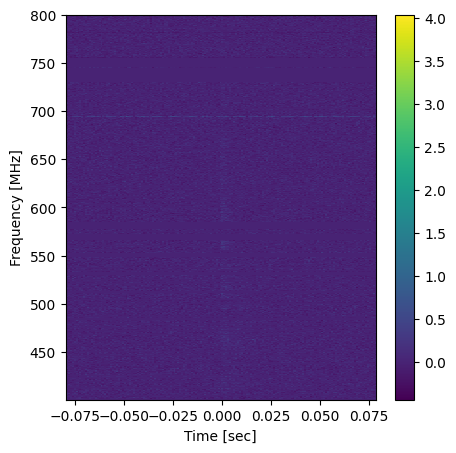

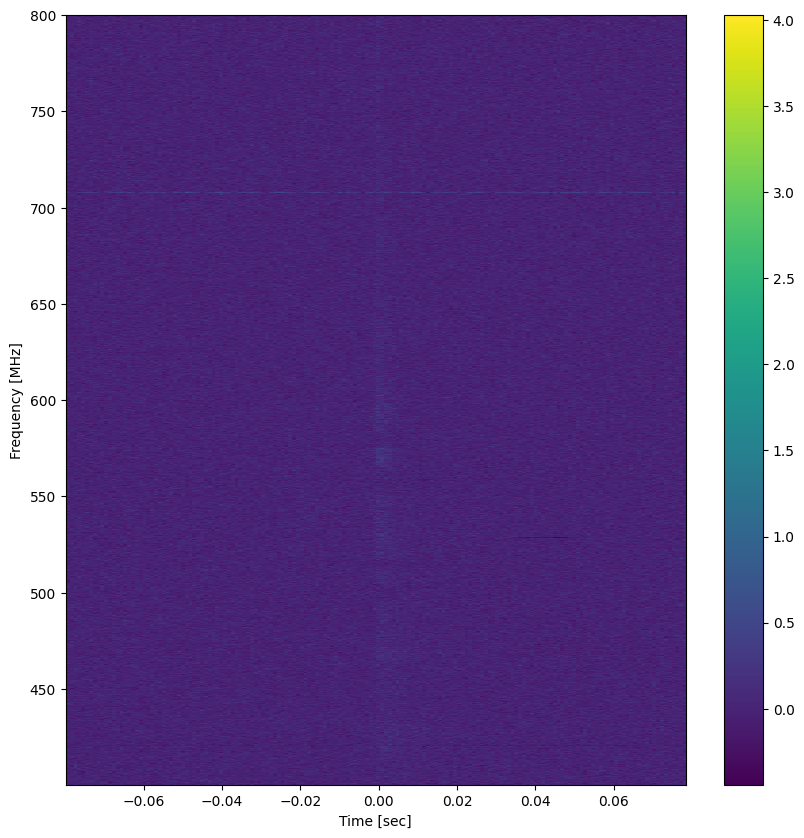

In [21]:
print("First plotting data with masked channels included")

fig = plt.figure(figsize=(5, 5))
img = plt.imshow(data * combined_flag,
                 aspect="auto",
                 origin="lower",
                 interpolation="nearest",
                 extent=(time[0], time[-1], freq[0], freq[-1]))
plt.colorbar(img)

# plt.xlabel("Time [msec]")
plt.xlabel("Time [sec]")
plt.ylabel("Frequency [MHz]")

print("Then plotting data with masked channels removed")

fig = plt.figure(figsize=(10, 10))
img = plt.imshow(data_reshaped,
                 aspect="auto",
                 origin="lower",
                 interpolation="nearest",
                 extent=(time[0], time[-1], freq[0], freq[-1]))
plt.colorbar(img)

# plt.xlabel("Time [msec]")
plt.xlabel("Time [sec]")
plt.ylabel("Frequency [MHz]")

#### Estimating noise

In [22]:
times_noise = jnp.asarray([i for i in time_array[0] if i<-10/1000]).flatten()
noise_data = data_reshaped[:,0:len(times_noise)]

len(times_noise)

72

Noise segments we will draw from


Text(0, 0.5, 'Frequency [MHz]')

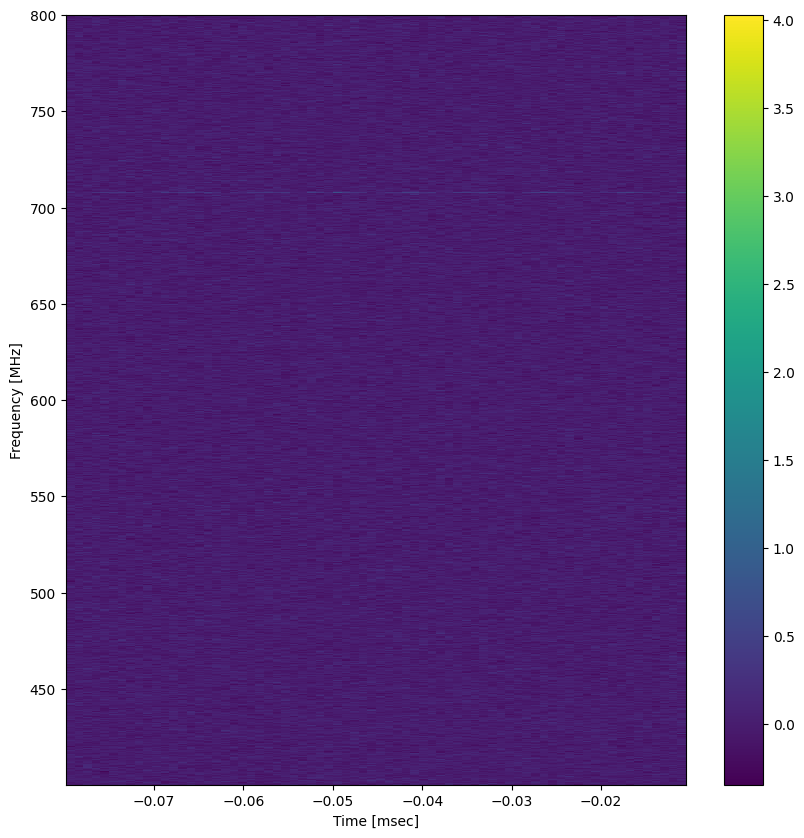

In [23]:
print("Noise segments we will draw from")
fig = plt.figure(figsize=(10, 10))
img = plt.imshow(noise_data,
                 aspect="auto",
                 origin="lower",
                 interpolation="nearest",
                 extent=(times_noise[0], times_noise[-1], freq[0], freq[-1]))
plt.colorbar(img)

plt.xlabel("Time [msec]")
plt.ylabel("Frequency [MHz]")

In [24]:
noise_median_estimates = jnp.asarray([jnp.median(data_reshaped[i,0:len(times_noise)]) for i in jnp.arange(len(freq_array_reshaped))])[:,None]


(array([2.000e+00, 1.000e+00, 1.000e+00, 3.500e+01, 3.102e+03, 3.400e+01,
        0.000e+00, 0.000e+00, 0.000e+00, 1.000e+00]),
 array([-0.2420903 , -0.18878564, -0.13548097, -0.08217631, -0.02887166,
         0.024433  ,  0.07773767,  0.13104232,  0.18434699,  0.23765166,
         0.29095632]),
 <BarContainer object of 10 artists>)

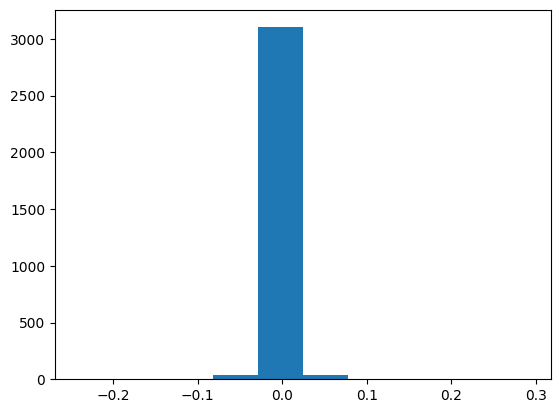

In [25]:
plt.hist(noise_median_estimates)

In [26]:
# 1. Calculate the median per frequency row
median = jnp.median(noise_data, axis=1, keepdims=True)

# 2. Calculate MAD: median(|x - median|)
mad = jnp.median(jnp.abs(noise_data - median), axis=1, keepdims=True)

# 3. Convert to sigma (1.4826 is the scaling factor for Normal dists)
sigma_estimates = mad * 1.4826

# Ensure no zeros (numerical floor)
sigma_estimates = jnp.clip(sigma_estimates, a_min=1e-10)

(array([1.450e+02, 1.024e+03, 1.399e+03, 5.350e+02, 6.600e+01, 4.000e+00,
        1.000e+00, 1.000e+00, 0.000e+00, 1.000e+00]),
 array([0.04278184, 0.05543489, 0.06808794, 0.08074099, 0.09339404,
        0.10604709, 0.11870014, 0.13135318, 0.14400624, 0.15665929,
        0.16931234]),
 <BarContainer object of 10 artists>)

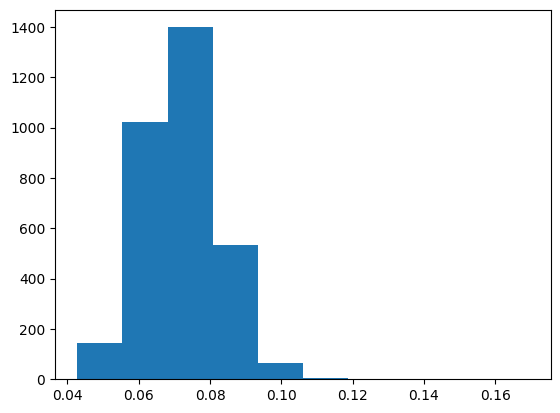

In [27]:
plt.hist(sigma_estimates)

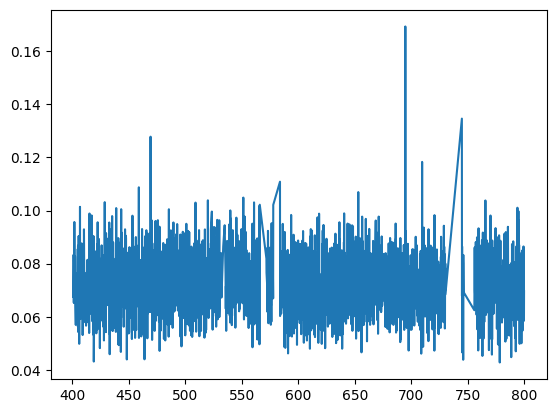

In [28]:
plt.plot(freq_array_reshaped, sigma_estimates)

#### Subtracting Noise Median from Data

In [29]:
data_reshaped = data_reshaped-noise_median_estimates

Text(0, 0.5, 'Frequency [MHz]')

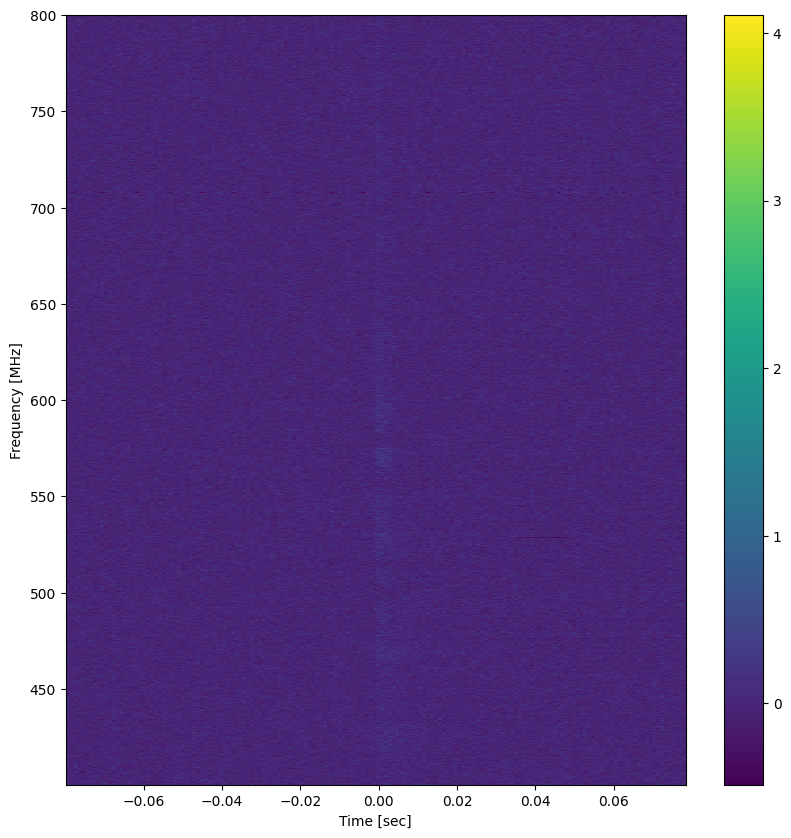

In [30]:
fig = plt.figure(figsize=(10, 10))
img = plt.imshow(data_reshaped,
                 aspect="auto",
                 origin="lower",
                 interpolation="nearest",
                 extent=(time[0], time[-1], freq[0], freq[-1]))
plt.colorbar(img)

# plt.xlabel("Time [msec]")
plt.xlabel("Time [sec]")
plt.ylabel("Frequency [MHz]")

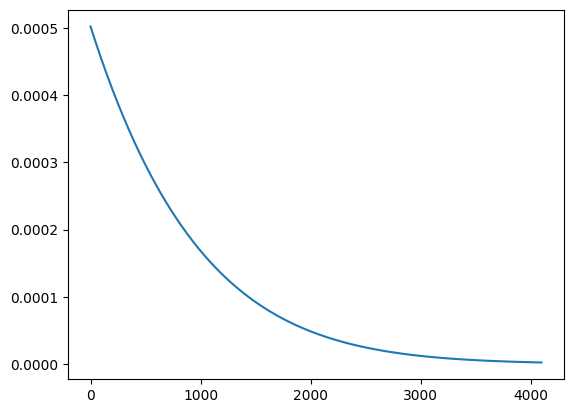

In [31]:
plt.plot(np.exp(-(freq_array)**2*1e-5)/(1+freq_array))

#### Further truncating data for computational convenience

In [32]:
# print("First plotting data with masked channels included")

# fig = plt.figure(figsize=(10, 10))
# img = plt.imshow(data * combined_flag,
#                  aspect="auto",
#                  origin="lower",
#                  interpolation="nearest",
#                  extent=(time[0], time[-1], freq[0], freq[-1]))
# plt.colorbar(img)

# # plt.xlabel("Time [msec]")
# plt.xlabel("Time [sec]")
# plt.ylabel("Frequency [MHz]")

# print("Then plotting data with masked channels removed")

# time_slice = [70,100]
# fig = plt.figure(figsize=(10, 10))
# img = plt.imshow(data_reshaped[:,time_slice[0]:time_slice[1]],
#                  aspect="auto",
#                  origin="lower",
#                  interpolation="nearest",
#                 extent=(time[time_slice[0]], time[time_slice[1]], freq[0], freq[-1]))
# plt.colorbar(img)

# # plt.xlabel("Time [msec]")
# plt.xlabel("Time [sec]")
# plt.ylabel("Frequency [MHz]")

In [33]:
# data_reshaped = data_reshaped[:,70:100]
# time_array = time_array[:,70:100]

#### Fourier transforming the data

In [34]:
L = time_array[0].shape[0]
dt = time_array[0][1] - time_array[0][0]
fourier_freqs = jnp.fft.rfftfreq(L, d=dt,dtype=jnp.float32)

In [35]:
data_reshaped_FFT = dt * jnp.fft.rfft(data_reshaped,axis=-1)

### TESTING LOG EVAL

In [87]:
### Defining necessary constants

# fixed / typical values
freq_channels_ref = 600.0
# gamma = 0.0
# beta = 0.0
delta = -4.0
epsilon = -2.0
# tau_ref = 0.0 #numpyro.sample(f"tau_ref_{i}", dist.Uniform(0.0, 0.01))
k_DM = (2.41*1e-4)**(-1) #pc^-1 * cm^3 * GHz^2 * s

constants_dict = {
    "freq_channels_ref": freq_channels_ref,
    "epsilon": epsilon,
    "k_DM": k_DM,
    "delta": delta
    #"tau_ref": tau_ref
}

len_freq_channel_array = len(freq_array_reshaped)
len_fourier_freq_array = len(fourier_freqs)

# define PSD
eta = 2*jnp.ones(len_fourier_freq_array)
eta = eta.at[0].set(1.0)
if L%2==0:
    eta = eta.at[-1].set(1.0)
PSD = eta * L * (dt**2) * sigma_estimates**2
sqrtPSD = jnp.sqrt(PSD)

In [90]:
freq_array_reshaped.shape

(12530, 1)

In [91]:
time_array.shape

(1, 162)

In [88]:

import time
import jax
import jax.numpy as jnp
from numpyro.infer.util import log_density

single_pulse_method = setup_model(constants_dict, freq_array_reshaped, time_array)


# --- 1. Set up model args/kwargs exactly as you pass to mcmc.run ---
model_args = (data_reshaped_FFT,)  # positional args your model takes, if any (likely none beyond kwargs)
model_kwargs = dict(
    data=data_reshaped_FFT,
    len_freq_channel_array=len_freq_channel_array,
    len_fourier_freq_array=len_fourier_freq_array,
    single_pulse_method=single_pulse_method,
    sigma_noise=sqrtPSD,
    n_pulses=1,
)
# NOTE: if `data` is passed as a kwarg (as in your model signature), drop it from model_args:
model_args = ()

# --- 2. Pick a fixed point in parameter space to evaluate at (any valid values) ---
init_params = {
    "DM_0": jnp.float32(0.0),
    "t0_0": jnp.float32(0.08),
    "sigma_0": jnp.float32(0.001),
    "alpha_0": jnp.float32(-1.0),
    "gamma_0": jnp.float32(0.0),
    "beta_0": jnp.float32(0.0),
    "tau_ref_0": jnp.float32(0.01),
}

# --- 3. Wrap log_density so it returns a scalar (log_density returns (logp, trace)) ---
def logp_fn(params):
    log_joint, _ = log_density(numpyro_model, model_args, model_kwargs, params)
    return log_joint

# --- 4. Time a single (uncompiled) forward evaluation ---
t0 = time.time()
val = logp_fn(init_params)
val.block_until_ready()
print("First (uncompiled) logp eval:", time.time() - t0, "s")

# --- 5. Time a JIT-compiled forward evaluation: compile time vs steady-state ---
logp_jit = jax.jit(logp_fn)

t0 = time.time()
val = logp_jit(init_params)
val.block_until_ready()
print("First jit call (includes compile):", time.time() - t0, "s")

t0 = time.time()
val = logp_jit(init_params)
val.block_until_ready()
print("Second jit call (steady-state, compiled):", time.time() - t0, "s")

# --- 6. Time gradient evaluation (this is what NUTS actually uses every leapfrog step) ---
grad_fn = jax.jit(jax.grad(logp_fn))

t0 = time.time()
grads = grad_fn(init_params)
jax.block_until_ready(grads)
print("First grad call (includes compile):", time.time() - t0, "s")

t0 = time.time()
grads = grad_fn(init_params)
jax.block_until_ready(grads)
print("Second grad call (steady-state, compiled):", time.time() - t0, "s")

First (uncompiled) logp eval: 0.7808928489685059 s
First jit call (includes compile): 0.34415698051452637 s
Second jit call (steady-state, compiled): 0.01009368896484375 s
First grad call (includes compile): 0.45440053939819336 s
Second grad call (steady-state, compiled): 0.015469789505004883 s


In [ ]:
First (uncompiled) logp eval: 0.792351245880127 s
First jit call (includes compile): 0.19496655464172363 s
Second jit call (steady-state, compiled): 0.001405954360961914 s
First grad call (includes compile): 0.48445773124694824 s
Second grad call (steady-state, compiled): 0.001661539077758789 s

#### TEST init vals

In [163]:
import jax.numpy as jnp
import jax.random as jrand
from jax.scipy.special import expit  # Sigmoid to undo NUTS logit transform
from numpyro.infer import NUTS, init_to_value

# 1. Parameter prior bounds (low, high)
bounds = {
    "DM_0": (-10.0, 10.0),
    "mean_arrival_time_0": (-0.02 + 0.08, 0.02 + 0.08),
    "sigma_0": (0.1 / 1000.0, 10.0 / 1000.0),
    "alpha_0": (-2.0, 0.0),
    "gamma_0": (-20.0, 10.0),
    "beta_0": (-20.0, 10.0),
    "tau_ref_0": (0.0, 0.1),
}

# 2. Desired physical values
target_physical = {
    "DM_0": jnp.array([0.0]),
    "mean_arrival_time_0": jnp.array([0.08]),
    "sigma_0": jnp.array([0.00041288]),
    "alpha_0": jnp.array([-1.661096]),
    "gamma_0": jnp.array([2.078152]),
    "beta_0": jnp.array([-7.629409]),
    "tau_ref_0": jnp.array([0.01]),
}

# 3. Transform physical targets to [0, 1] base scale for init_to_value
init_vals_base = {
    f"{name}_base": (val - bounds[name][0])
    / (bounds[name][1] - bounds[name][0])
    for name, val in target_physical.items()
}

# 4. Initialize NUTS kernel
kernel = NUTS(
    numpyro_model,
    dense_mass=True,
    init_strategy=init_to_value(values=init_vals_base),
)

init_state = kernel.init(
    jrand.PRNGKey(1),
    num_warmup=500,
    model_kwargs={
        "data": data_reshaped_FFT,
        "len_freq_channel_array": len_freq_channel_array,
        "len_fourier_freq_array": len_fourier_freq_array,
        "single_pulse_method": single_pulse_method,
        "sigma_noise": sqrtPSD,
        "n_pulses": 1,
    },
)

# 5. Transform init_state.z back to physical space to confirm
print(f"{'Parameter':<20} | {'Target Physical':<18} | {'Actual Init Physical'}")
print("-" * 60)
for site_name, z_val in init_state.z.items():
    param_name = site_name.replace("_base", "")
    if param_name in bounds:
        low, high = bounds[param_name]
        base_val = expit(z_val)  # Map unconstrained R -> [0, 1]
        phys_val = low + base_val * (high - low)
        print(
            f"{param_name:<20} | {float(target_physical[param_name][0]):<18.6f} | {float(phys_val[0]):.6f}"
        )

Parameter            | Target Physical    | Actual Init Physical
------------------------------------------------------------
DM_0                 | 0.000000           | 0.000000
sigma_0              | 0.000413           | 0.000413
alpha_0              | -1.661096          | -1.661096
gamma_0              | 2.078152           | 2.078152
beta_0               | -7.629409          | -7.629410
tau_ref_0            | 0.010000           | 0.010000


#### Test degeneracies

Physical parameters:
DM_0 0.00016399999999983095
mean_arrival_time_0 0.0785813952
sigma_0 0.0006622692130000001
alpha_0 -0.72304214
gamma_0 -4.068831800000002
beta_0 -6.7411069999999995
tau_ref_0 0.002193132


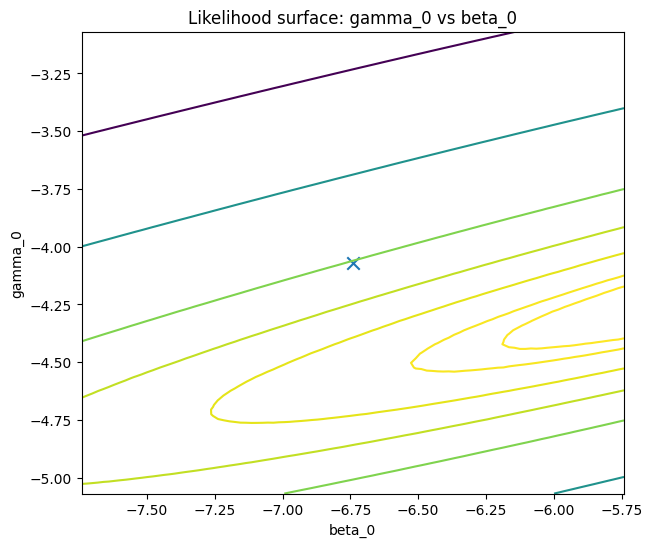

In [48]:
# import numpy as np
# import matplotlib.pyplot as plt
# import jax.numpy as jnp

# ============================================================
# Convert NUTS base initialization values -> physical values
# ============================================================

base_best = {
    "DM_0_base": 0.5000082,
    "mean_arrival_time_0_base": 0.46453488,
    "sigma_0_base": 0.05679487,
    "alpha_0_base": 0.63847893,
    "gamma_0_base": 0.53103894,
    "beta_0_base": 0.4419631,
    "tau_ref_0_base": 0.02193132,
}

bounds = {
    "DM_0": (-10.0, 10.0),
    "mean_arrival_time_0": (0.06, 0.10),
    "sigma_0": (0.0001, 0.01),
    "alpha_0": (-2.0, 0.0),
    "gamma_0": (-20.0, 10.0),
    "beta_0": (-20.0, 10.0),
    "tau_ref_0": (0.0, 0.1),
}


best = {}

for name, (low, high) in bounds.items():
    base_name = name + "_base"
    best[name] = low + base_best[base_name] * (high - low)

print("Physical parameters:")
for k, v in best.items():
    print(k, v)


# ============================================================
# Define likelihood
# ============================================================

def log_likelihood(params):

    params_dict = {
        "DM": params["DM_0"],
        "mean_arrival_time": params["mean_arrival_time_0"],
        "sigma": params["sigma_0"],
        "alpha": params["alpha_0"],
        "gamma": params["gamma_0"],
        "beta": params["beta_0"],
        "tau_ref": params["tau_ref_0"],
    }

    pred = single_pulse_method(params_dict)

    resid = data_reshaped_FFT - pred

    logp = -0.5 * jnp.sum(
        (
            jnp.real(resid)**2 +
            jnp.imag(resid)**2
        )
        / (sqrtPSD**2)
    )

    return logp


# ============================================================
# Choose two parameters to scan HERE ONLY
# ============================================================

param_x = "beta_0"
param_y = "gamma_0"


# ============================================================
# Define scan ranges
# ============================================================

if param_x in ["sigma_0", "tau_ref_0"]:
    x_grid = np.linspace(
        best[param_x] * 0.3,
        best[param_x] * 3.0,
        100
    )
else:
    x_grid = np.linspace(
        best[param_x] - 1.0,
        best[param_x] + 1.0,
        100
    )


if param_y in ["sigma_0", "tau_ref_0"]:
    y_grid = np.linspace(
        max(best[param_y] * 0.3, 1e-8),
        best[param_y] * 3.0,
        100
    )
else:
    y_grid = np.linspace(
        best[param_y] - 1.0,
        best[param_y] + 1.0,
        100
    )


# ============================================================
# Evaluate likelihood grid
# ============================================================

loglike_grid = np.zeros(
    (len(y_grid), len(x_grid))
)


for i, y in enumerate(y_grid):
    for j, x in enumerate(x_grid):

        params = best.copy()

        params[param_x] = x
        params[param_y] = y

        loglike_grid[i, j] = float(log_likelihood(params))


# normalize
loglike_grid -= np.max(loglike_grid)


# ============================================================
# Plot
# ============================================================

plt.figure(figsize=(7,6))

levels = [-100, -50, -20, -10, -5, -2, -1]

plt.contour(
    x_grid,
    y_grid,
    loglike_grid,
    levels=levels
)

plt.scatter(
    best[param_x],
    best[param_y],
    marker="x",
    s=80
)

plt.xlabel(param_x)
plt.ylabel(param_y)

if param_x in ["sigma_0", "tau_ref_0"]:
    plt.xscale("log")

if param_y in ["sigma_0", "tau_ref_0"]:
    plt.yscale("log")

plt.title(f"Likelihood surface: {param_y} vs {param_x}")

plt.show()

#### Running model

In [37]:
### Defining necessary constants

# fixed / typical values
freq_channels_ref = 600.0
# gamma = 0.0
# beta = 0.0
delta = -4.0
epsilon = -2.0
# tau_ref = 0.0 #numpyro.sample(f"tau_ref_{i}", dist.Uniform(0.0, 0.01))
k_DM = (2.41*1e-4)**(-1) #pc^-1 * cm^3 * GHz^2 * s

constants_dict = {
    "freq_channels_ref": freq_channels_ref,
    "epsilon": epsilon,
    "k_DM": k_DM,
    "delta": delta
    #"tau_ref": tau_ref
}

len_freq_channel_array = len(freq_array_reshaped)
len_fourier_freq_array = len(fourier_freqs)

# define PSD
eta = 2*jnp.ones(len_fourier_freq_array)
eta = eta.at[0].set(1.0)
if L%2==0:
    eta = eta.at[-1].set(1.0)
PSD = eta * L * (dt**2) * sigma_estimates**2
sqrtPSD = jnp.sqrt(PSD)

In [40]:
init_vals_physical = {'DM_0_base': 0.5000082,
 't0_0_base': 0.46453488,
 'sigma_0_base': 0.05679487,
 'alpha_0_base': 0.63847893,
 'gamma_0_base': 0.53103894,
 'beta_0_base': 0.4419631,
 'tau_ref_0_base': 0.02193132}

In [41]:
### setting up model method
single_pulse_method = setup_model(constants_dict, freq_array_reshaped, time_array)

#running sampler

#initial_parameter_guess = {"alpha_0": -1.6610962224298984, "t0_0": 0, "sigma_0": 0.0004128824360633611, "DM_0": 0, "gamma_0": 2.078152594885448, "beta_0":-7.62940918595922, "tau_ref_0":0.01}
#initial_parameter_guess = {"alpha_0": -1.6610962224298984, "t0_0": 0, "sigma_0": 0.0004128824360633611, "DM_0": 0, "gamma_0": 2.078152594885448, "beta_0":-7.62940918595922, "tau_ref_0":0.01}

kernel = NUTS(numpyro_model, dense_mass=True, init_strategy=init_to_value(values=init_vals_physical))
seed = 1
rng_key = jrand.PRNGKey(seed)

num_samples = 500
num_warmup = 500
num_chains = 4
mcmc = MCMC(kernel, num_warmup=num_warmup, num_samples=num_samples, num_chains=num_chains, chain_method="parallel" )


In [193]:
mcmc.run(rng_key=rng_key, data=data_reshaped_FFT, len_freq_channel_array=len_freq_channel_array, len_fourier_freq_array=len_fourier_freq_array, single_pulse_method = single_pulse_method, sigma_noise = sqrtPSD, n_pulses=1,extra_fields=("num_steps","accept_prob","diverging","potential_energy"))

# mcmc = MCMC(kernel, num_warmup=500, num_samples=500, num_chains=4, chain_method="parallel" )
# mcmc.run(rng_key=rng_key, data=data_reshaped_FFT, len_freq_channel_array=len_freq_channel_array, len_fourier_freq_array=len_fourier_freq_array, single_pulse_method = single_pulse_method, sigma_noise = sqrtPSD, n_pulses=1, chunk_size=805, extra_fields=("num_steps",))
# print(mcmc.get_extra_fields()["num_steps"].mean())

# samples = mcmc.get_samples()
# extra = mcmc.get_extra_fields(group_by_chain=True)

# # Create an InferenceData object
# mcmc_data = az.from_dict(
#     posterior=samples,
#     sample_stats=extra
# )

Compiling.. :   0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

Compiling.. :   0%|          | 0/1000 [00:00<?, ?it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


Running chain 1:   0%|          | 0/1000 [00:02<?, ?it/s]

Running chain 2:   0%|          | 0/1000 [00:02<?, ?it/s]


Running chain 0:   5%|▌         | 50/1000 [01:43<31:58,  2.02s/it]


Running chain 3:   5%|▌         | 50/1000 [01:50<34:14,  2.16s/it]

Running chain 1:   5%|▌         | 50/1000 [03:34<1:07:15,  4.25s/it]


Running chain 3:  10%|█         | 100/1000 [04:37<42:50,  2.86s/it]

Running chain 1:  10%|█         | 100/1000 [05:44<49:05,  3.27s/it] 


Running chain 3:  15%|█▌        | 150/1000 [06:36<37:25,  2.64s/it]


Running chain 0:  15%|█▌        | 150/1000 [10:26<1:04:54,  4.58s/it]A

Running chain 1:  15%|█▌        | 150/1000 [10:59<1:06:01,  4.66s/it]

Running chain 2:  20%|██        | 200/1000 [14:58<1:04:40,  4.85s/it]


Running chain 0:  20%|██        | 200/1000 [15:57<

In [168]:
extra = mcmc.get_extra_fields()
print("total steps:", extra["num_steps"].sum())
print("mean steps:", extra["num_steps"].mean())
print("max steps:", extra["num_steps"].max())
print("accept prob:",extra["accept_prob"].mean())
print("diverging",extra["diverging"].sum())


total steps: 24220
mean steps: 12.110001
max steps: 63
accept prob: 0.853397
diverging 0


In [169]:
mcmc_data = az.from_numpyro(mcmc, log_likelihood={}, posterior_predictive={})

In [170]:
az.summary(mcmc_data, round_to=3)

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
DM_0,-0.002,0.011,-0.021,0.018,0.000,0.000,2723.150,1254.301,1.002
DM_0_base,0.500,0.001,0.499,0.501,0.000,0.000,2723.150,1254.301,1.002
alpha_0,-0.704,0.044,-0.787,-0.621,0.001,0.001,1471.771,955.710,1.001
alpha_0_base,0.648,0.022,0.607,0.690,0.001,0.001,1471.771,955.710,1.001
beta_0,-6.581,0.722,-7.941,-5.297,0.018,0.018,1590.072,1311.063,1.004
beta_0_base,0.447,0.024,0.402,0.490,0.001,0.001,1590.072,1311.063,1.004
gamma_0,-4.029,0.198,-4.395,-3.669,0.005,0.005,1670.884,1358.574,1.002
gamma_0_base,0.532,0.007,0.520,0.544,0.000,0.000,1670.884,1358.574,1.002
sigma_0,0.001,0.000,0.001,0.001,0.000,0.000,1463.847,1048.769,1.002
sigma_0_base,0.055,0.007,0.043,0.067,0.000,0.000,1463.847,1048.769,1.002


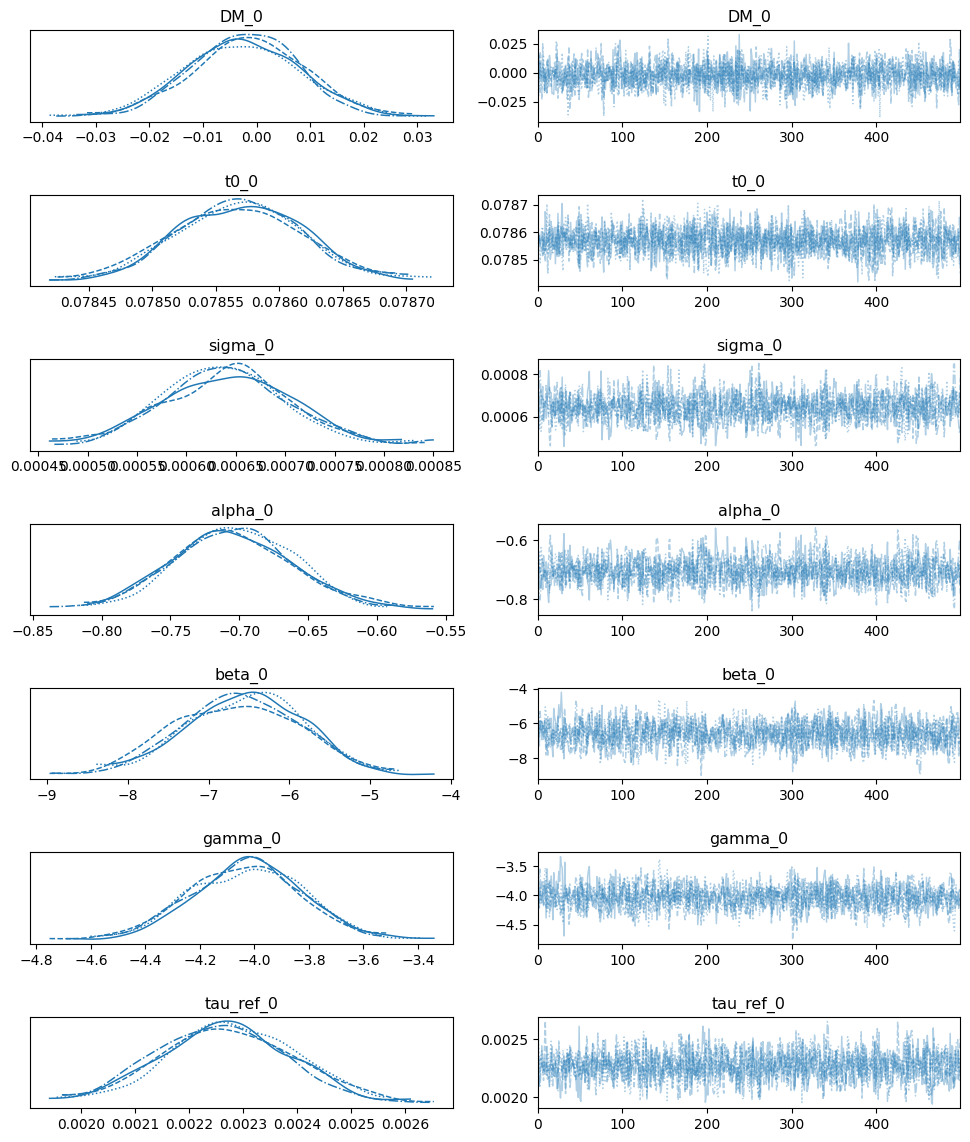

In [171]:
axes = az.plot_trace(mcmc_data, var_names=["DM_0", "t0_0", "sigma_0", "alpha_0", "beta_0", "gamma_0", "tau_ref_0"],combined=False,divergences=False);
# axes = az.plot_trace(mcmc_data, var_names=["DM_0", "t0_0", "sigma_0", "alpha_0", "beta_0", "gamma_0"],combined=False,divergences=False);

# for i, var in enumerate(["DM_0", "t0_0", "sigma_0", "alpha_0"]):
#     # posterior panel only
#     axes[i, 0].axvline(true_vals[var], color="black", linestyle="--", lw=2)
    
plt.subplots_adjust(hspace=0.8)  # increase vertical spacing

In [160]:
mcmc_data

Inference data with groups:
	> posterior
	> sample_stats
	> observed_data

In [138]:
len(extra["potential_energy"])

2000

In [139]:
extra["potential_energy"]

Array([-833006.06, -833005.7 , -833005.1 , ..., -833005.9 , -832999.75,
       -833000.5 ], dtype=float32)

In [140]:
best_idx

Array(1551, dtype=int32)

In [143]:
chain_for_init = int(np.floor(best_idx/num_samples))
best_idx = jnp.argmin(log_probs)%num_samples
print(chain_for_init, best_idx)

0 51


In [156]:
log_probs = extra["potential_energy"]  # note: this is -log_prob
best_idx = jnp.argmin(log_probs)%num_samples # minimize potential energy = maximize log_prob
chain_for_init = int(np.floor(best_idx/num_samples))

init_vals_physical = {
    "DM_0_base": mcmc_data.posterior["DM_0_base"].sel(chain=chain_for_init,draw=best_idx).values,
    "t0_0_base": mcmc_data.posterior["t0_0_base"].sel(chain=chain_for_init,draw=best_idx).values,
    "sigma_0_base": mcmc_data.posterior["sigma_0_base"].sel(chain=chain_for_init,draw=best_idx).values,
    "alpha_0_base": mcmc_data.posterior["alpha_0_base"].sel(chain=chain_for_init,draw=best_idx).values,
    "gamma_0_base": mcmc_data.posterior["gamma_0_base"].sel(chain=chain_for_init,draw=best_idx).values,
    "beta_0_base": mcmc_data.posterior["beta_0_base"].sel(chain=chain_for_init,draw=best_idx).values,
    "tau_ref_0_base": mcmc_data.posterior["tau_ref_0_base"].sel(chain=chain_for_init,draw=best_idx).values,
}

init_vals_physical

{'DM_0_base': array(0.5000082, dtype=float32),
 't0_0_base': array(0.46453488, dtype=float32),
 'sigma_0_base': array(0.05679487, dtype=float32),
 'alpha_0_base': array(0.63847893, dtype=float32),
 'gamma_0_base': array(0.53103894, dtype=float32),
 'beta_0_base': array(0.4419631, dtype=float32),
 'tau_ref_0_base': array(0.02193132, dtype=float32)}

#### Plotting model with posterior draws

In [212]:
import sys

In [213]:
sys.getsizeof(mcmc_data)

56

In [150]:
mcmc_data

Inference data with groups:
	> posterior
	> sample_stats
	> observed_data

In [104]:
# sns.kdeplot(mcmc_data.posterior.sel(chain=0).DM_0.values.flatten())
# sns.kdeplot(mcmc_data.posterior.sel(chain=1).DM_0.values.flatten())
# sns.kdeplot(mcmc_data.posterior.sel(chain=2).DM_0.values.flatten())
# sns.kdeplot(mcmc_data.posterior.sel(chain=3).DM_0.values.flatten())

In [105]:
# sns.kdeplot(mcmc_data.posterior.sel(chain=0).sigma_0.values.flatten())
# sns.kdeplot(mcmc_data.posterior.sel(chain=1).sigma_0.values.flatten())
# sns.kdeplot(mcmc_data.posterior.sel(chain=2).sigma_0.values.flatten())
# sns.kdeplot(mcmc_data.posterior.sel(chain=3).sigma_0.values.flatten())

In [106]:
# sns.kdeplot(mcmc_data.posterior.sel(chain=0).t0_0.values.flatten())
# sns.kdeplot(mcmc_data.posterior.sel(chain=1).t0_0.values.flatten())
# sns.kdeplot(mcmc_data.posterior.sel(chain=2).t0_0.values.flatten())
# sns.kdeplot(mcmc_data.posterior.sel(chain=3).t0_0.values.flatten())

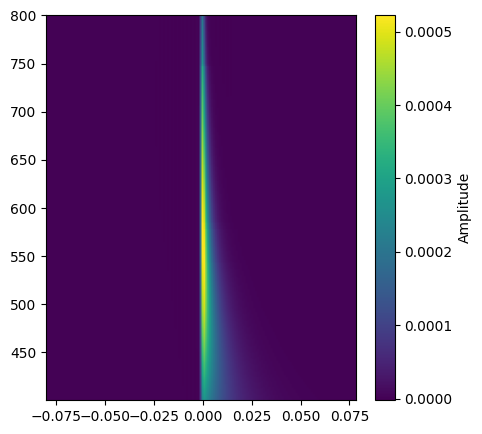

In [29]:
draw = 220
chain = 0

params_dict = {
    # Pulse and dispersion
    "DM": mcmc_data.posterior.sel(chain=chain, draw=draw).DM_0.values[()],           # pc/cm^3
    "freq_ref": 600.0,     # MHz, reference frequency near middle of band
    "tau_ref": mcmc_data.posterior.sel(chain=chain, draw=draw).tau_ref_0.values[()], # mcmc_data.posterior.sel(chain=0, draw=0).tau_ref_0.values[()],#0.000, # 0.015,      # s, scatter broadening at freq_ref
    "epsilon": -2.0,        # dispersion exponent
    
    # Temporal shape
    "sigma": mcmc_data.posterior.sel(chain=chain, draw=draw).sigma_0.values[()],        # s, intrinsic width of pulse
    
    # Amplitude / spectrum
    "alpha": mcmc_data.posterior.sel(chain=chain, draw=draw).alpha_0.values[()],          # log10 global amplitude
    "gamma": mcmc_data.posterior.sel(chain=chain, draw=draw).gamma_0.values[()],         # spectral index for SED
    "beta": mcmc_data.posterior.sel(chain=chain, draw=draw).beta_0.values[()],           # running spectral index
    "delta": -4.0,          # scatter-frequency exponent
    "mean_arrival_time": mcmc_data.posterior.sel(chain=chain, draw=draw).t0_0.values[()],
    "k_DM": (2.41*1e-4)**(-1)
}

# fixed / typical values
freq_channels_ref = 600.0
# gamma = 0.0
# beta = 0.0
delta = -4.0
epsilon = -2.0
tau_ref = 0.0 #numpyro.sample(f"tau_ref_{i}", dist.Uniform(0.0, 0.01))
k_DM = (2.41*1e-4)**(-1) #pc^-1 * cm^3 * GHz^2 * s

constants_dict = {
    "freq_channels_ref": freq_channels_ref,
    "epsilon": epsilon,
    "k_DM": k_DM,
    "delta": delta,
    "tau_ref": tau_ref
}

# freq_array = jnp.arange(400,800,1, dtype=jnp.float32)[:, None]  # (nfreq,1), MHz
# time_array = jnp.arange(1,3,0.01, dtype=jnp.float32)[None, :] # (1,ntime), s
# #single_pulse_model(params_dict, freq_array, time_array)
single_pulse_method = setup_model(constants_dict, freq_array_reshaped, time_array)

M = single_pulse_method(params_dict)
M_TD_sampled = 1/(L*dt) * jnp.fft.irfft(M,axis=-1)
fig = plt.figure(figsize=(5, 5))
plt.imshow(
    M_TD_sampled,
    aspect='auto',
    origin='lower',
    cmap = "viridis",
    extent=(time[0], time[-1], freq[0], freq[-1])
)
plt.colorbar(label="Amplitude")


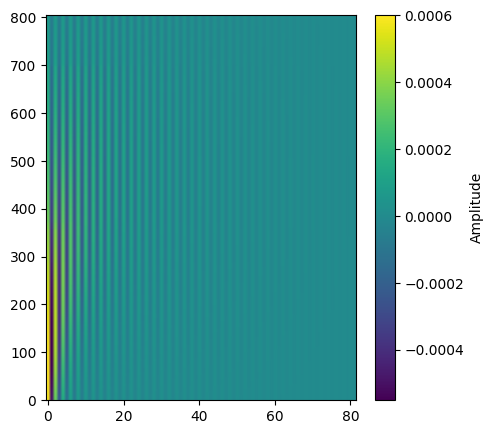

In [176]:
draw = 220
chain = 0

params_dict = {
    # Pulse and dispersion
    "DM": mcmc_data.posterior.sel(chain=chain, draw=draw).DM_0.values[()],           # pc/cm^3
    "freq_ref": 600.0,     # MHz, reference frequency near middle of band
    "tau_ref": mcmc_data.posterior.sel(chain=chain, draw=draw).tau_ref_0.values[()], # mcmc_data.posterior.sel(chain=0, draw=0).tau_ref_0.values[()],#0.000, # 0.015,      # s, scatter broadening at freq_ref
    "epsilon": -2.0,        # dispersion exponent
    
    # Temporal shape
    "sigma": mcmc_data.posterior.sel(chain=chain, draw=draw).sigma_0.values[()],        # s, intrinsic width of pulse
    
    # Amplitude / spectrum
    "alpha": mcmc_data.posterior.sel(chain=chain, draw=draw).alpha_0.values[()],          # log10 global amplitude
    "gamma": mcmc_data.posterior.sel(chain=chain, draw=draw).gamma_0.values[()],         # spectral index for SED
    "beta": mcmc_data.posterior.sel(chain=chain, draw=draw).beta_0.values[()],           # running spectral index
    "delta": -4.0,          # scatter-frequency exponent
    "mean_arrival_time": mcmc_data.posterior.sel(chain=chain, draw=draw).t0_0.values[()],
    "k_DM": (2.41*1e-4)**(-1)
}

# fixed / typical values
freq_channels_ref = 600.0
# gamma = 0.0
# beta = 0.0
delta = -4.0
epsilon = -2.0
tau_ref = 0.0 #numpyro.sample(f"tau_ref_{i}", dist.Uniform(0.0, 0.01))
k_DM = (2.41*1e-4)**(-1) #pc^-1 * cm^3 * GHz^2 * s

constants_dict = {
    "freq_channels_ref": freq_channels_ref,
    "epsilon": epsilon,
    "k_DM": k_DM,
    "delta": delta,
    "tau_ref": tau_ref
}

# freq_array = jnp.arange(400,800,1, dtype=jnp.float32)[:, None]  # (nfreq,1), MHz
# time_array = jnp.arange(1,3,0.01, dtype=jnp.float32)[None, :] # (1,ntime), s
# #single_pulse_model(params_dict, freq_array, time_array)
single_pulse_method = setup_model(constants_dict, freq_array_reshaped, time_array)

M = single_pulse_method(params_dict)
M_TD_sampled = 1/(L*dt) * jnp.fft.irfft(M,axis=-1)
fig = plt.figure(figsize=(5, 5))
plt.imshow(
    M.real,
    aspect='auto',
    origin='lower',
    cmap = "viridis"
)
plt.colorbar(label="Amplitude")


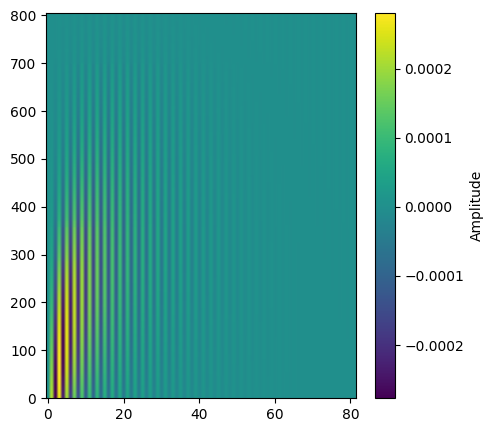

In [177]:
draw = 220
chain = 0

params_dict = {
    # Pulse and dispersion
    "DM": mcmc_data.posterior.sel(chain=chain, draw=draw).DM_0.values[()],           # pc/cm^3
    "freq_ref": 600.0,     # MHz, reference frequency near middle of band
    "tau_ref": mcmc_data.posterior.sel(chain=chain, draw=draw).tau_ref_0.values[()], # mcmc_data.posterior.sel(chain=0, draw=0).tau_ref_0.values[()],#0.000, # 0.015,      # s, scatter broadening at freq_ref
    "epsilon": -2.0,        # dispersion exponent
    
    # Temporal shape
    "sigma": mcmc_data.posterior.sel(chain=chain, draw=draw).sigma_0.values[()],        # s, intrinsic width of pulse
    
    # Amplitude / spectrum
    "alpha": mcmc_data.posterior.sel(chain=chain, draw=draw).alpha_0.values[()],          # log10 global amplitude
    "gamma": mcmc_data.posterior.sel(chain=chain, draw=draw).gamma_0.values[()],         # spectral index for SED
    "beta": mcmc_data.posterior.sel(chain=chain, draw=draw).beta_0.values[()],           # running spectral index
    "delta": -4.0,          # scatter-frequency exponent
    "mean_arrival_time": mcmc_data.posterior.sel(chain=chain, draw=draw).t0_0.values[()],
    "k_DM": (2.41*1e-4)**(-1)
}

# fixed / typical values
freq_channels_ref = 600.0
# gamma = 0.0
# beta = 0.0
delta = -4.0
epsilon = -2.0
tau_ref = 0.0 #numpyro.sample(f"tau_ref_{i}", dist.Uniform(0.0, 0.01))
k_DM = (2.41*1e-4)**(-1) #pc^-1 * cm^3 * GHz^2 * s

constants_dict = {
    "freq_channels_ref": freq_channels_ref,
    "epsilon": epsilon,
    "k_DM": k_DM,
    "delta": delta,
    "tau_ref": tau_ref
}

# freq_array = jnp.arange(400,800,1, dtype=jnp.float32)[:, None]  # (nfreq,1), MHz
# time_array = jnp.arange(1,3,0.01, dtype=jnp.float32)[None, :] # (1,ntime), s
# #single_pulse_model(params_dict, freq_array, time_array)
single_pulse_method = setup_model(constants_dict, freq_array_reshaped, time_array)

M = single_pulse_method(params_dict)
M_TD_sampled = 1/(L*dt) * jnp.fft.irfft(M,axis=-1)
fig = plt.figure(figsize=(5, 5))
plt.imshow(
    M.imag,
    aspect='auto',
    origin='lower',
    cmap = "viridis"
)
plt.colorbar(label="Amplitude")


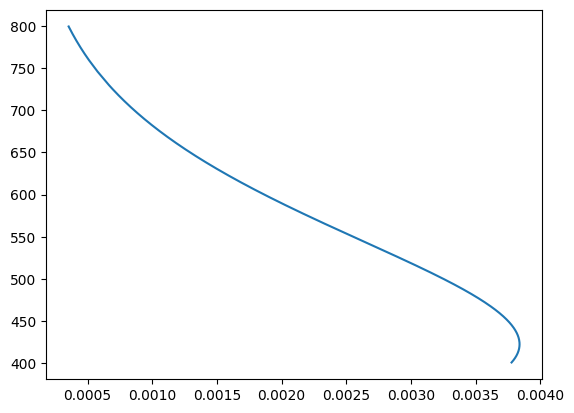

In [143]:
F = jnp.sum(M_TD_sampled, axis=1)
plt.plot(F,freq_array_reshaped)

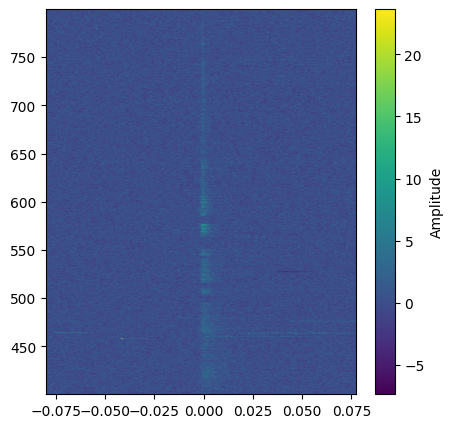

In [169]:
params_dict = {
    # Pulse and dispersion
    "DM": mcmc_data.posterior.sel(chain=0, draw=0).DM_0.values[()],           # pc/cm^3
    "freq_ref": 600.0,     # MHz, reference frequency near middle of band
    "tau_ref": mcmc_data.posterior.sel(chain=0, draw=0).tau_ref_0.values[()] ,#0.000, # 0.015,      # s, scatter broadening at freq_ref
    "epsilon": -2.0,        # dispersion exponent
    
    # Temporal shape
    "sigma": mcmc_data.posterior.sel(chain=0, draw=0).sigma_0.values[()],        # s, intrinsic width of pulse
    
    # Amplitude / spectrum
    "alpha": mcmc_data.posterior.sel(chain=0, draw=0).alpha_0.values[()],          # log10 global amplitude
    "gamma": mcmc_data.posterior.sel(chain=0, draw=0).gamma_0.values[()],         # spectral index for SED
    "beta": mcmc_data.posterior.sel(chain=0, draw=0).beta_0.values[()],           # running spectral index
    "delta": -4.0,          # scatter-frequency exponent
    "mean_arrival_time": mcmc_data.posterior.sel(chain=0, draw=0).t0_0.values[()],
    "k_DM": (2.41*1e-4)**(-1)

    
}

# freq_array = jnp.arange(400,800,1, dtype=jnp.float32)[:, None]  # (nfreq,1), MHz
# time_array = jnp.arange(1,3,0.01, dtype=jnp.float32)[None, :] # (1,ntime), s
# #single_pulse_model(params_dict, freq_array, time_array)
fig = plt.figure(figsize=(5, 5))
plt.imshow(
    (data_reshaped-M_TD_sampled)/sigma_estimates,
    aspect='auto',
    origin='lower',
    extent=[time_array[0][0], time_array[0][-1], freq_array.T[0][0], freq_array.T[0][-1]],
    cmap = "viridis",
)
plt.colorbar(label="Amplitude")


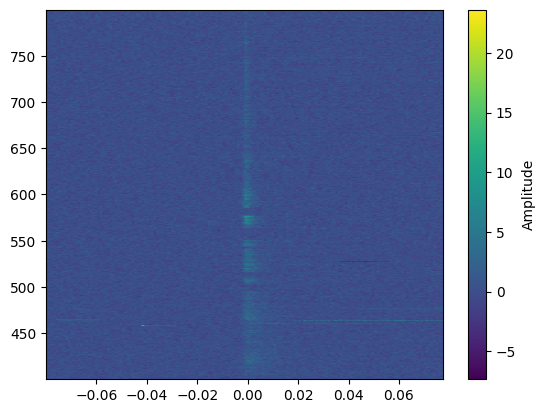

In [150]:
plt.imshow(
    (data_reshaped)/sigma_estimates,
    aspect='auto',
    origin='lower',
    extent=[time_array[0][0], time_array[0][-1], freq_array.T[0][0], freq_array.T[0][-1]],
    cmap = "viridis",
)
plt.colorbar(label="Amplitude")


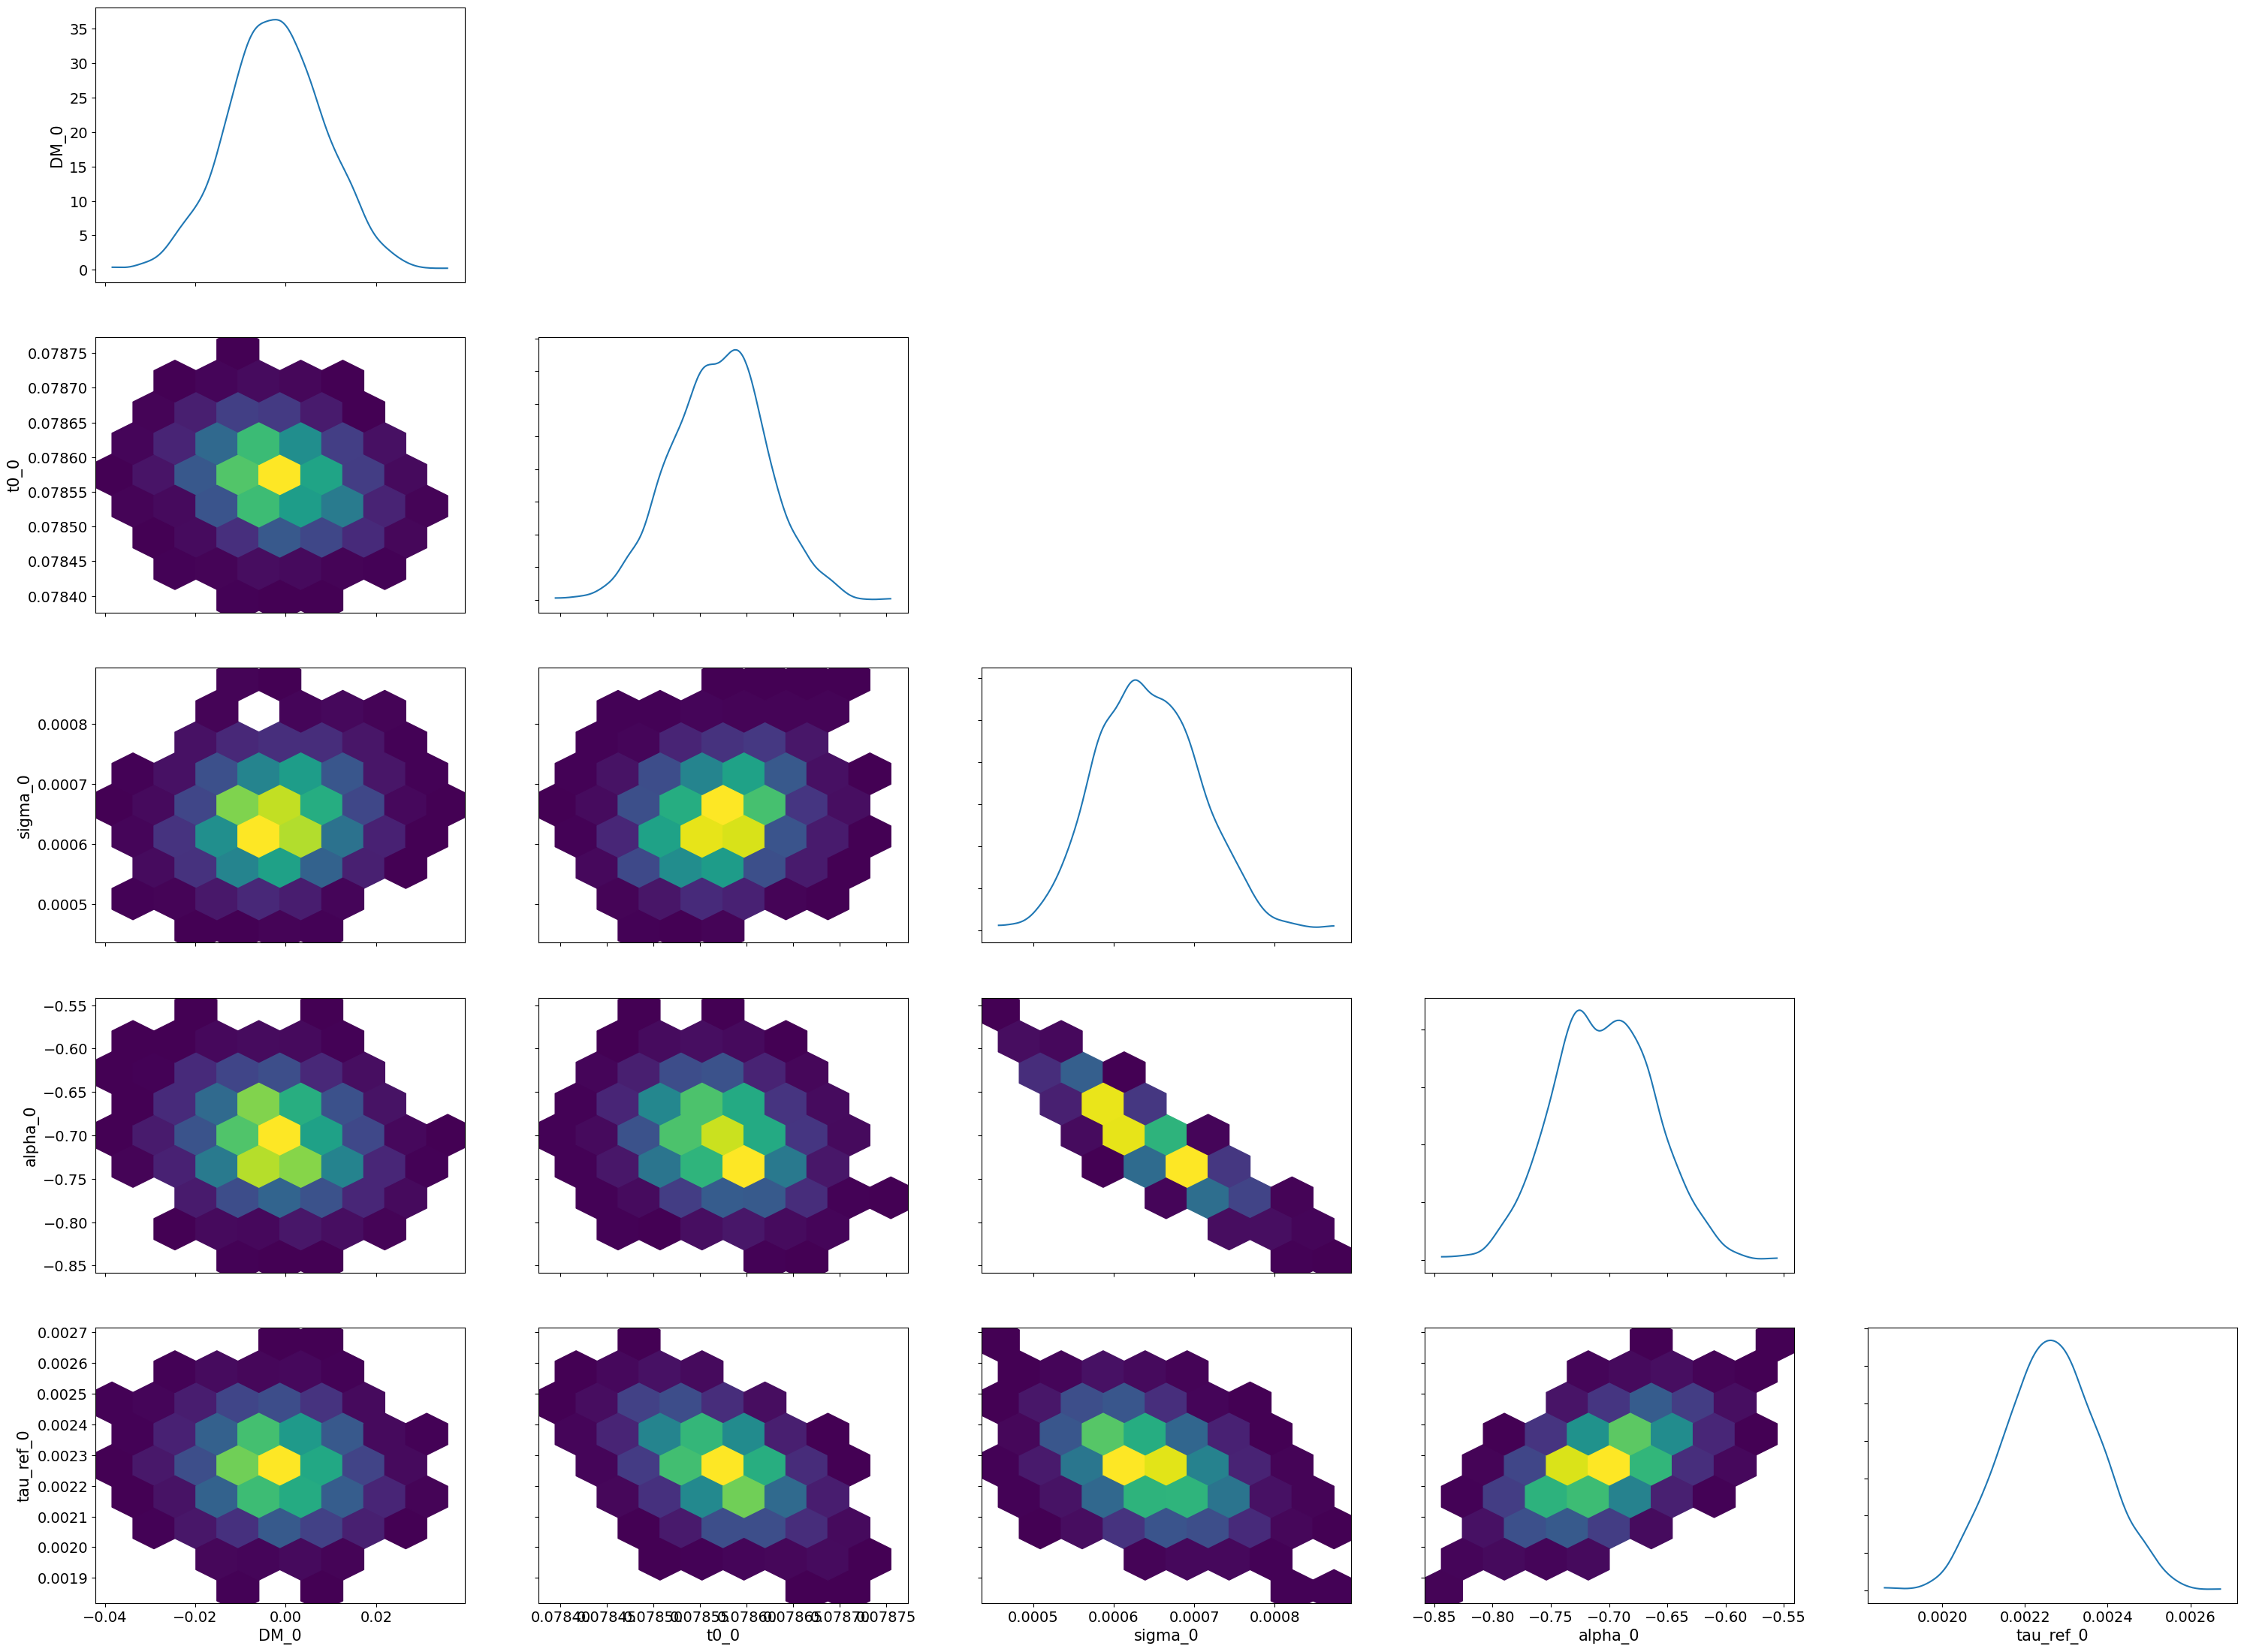

In [172]:
az.plot_pair(
    mcmc_data,
    var_names=["DM_0", "t0_0", "sigma_0", "alpha_0", "tau_ref_0" ],#, "DM_1", "t0_1", "sigma_1", "alpha_1"],
    kind="hexbin",
    marginals=True
);

#### SNR

In [95]:
def optimal_snr(noise, model):
    return jnp.sqrt(jnp.sum((jnp.abs(model)**2) / ((noise)**2)))

In [96]:
jnp.sqrt(optimal_snr(sigma_estimates, data_reshaped[:,80:90])**2-10000)

Array(111.288826, dtype=float32)

In [120]:
optimal_snr(sigma_estimates, M_TD_sampled)

Array(0.5895686, dtype=float32)

### Fake data

In [15]:
params_dict = {
    # Pulse and dispersion
    "DM": 5.0,           # pc/cm^3
    # "freq_ref": 600.0,     # MHz, reference frequency near middle of band
    # # "tau_ref": 0, # 0.015,      # s, scatter broadening at freq_ref
    # "epsilon": -2.0,        # dispersion exponent
    
    # Temporal shape
    "sigma": 0.01,        # s, intrinsic width of pulse
    
    # Amplitude / spectrum
    "alpha": -2.0,          # log10 global amplitude
    "gamma": 0.0,         # spectral index for SED
    "beta": 0.0,           # running spectral index
    # "delta": -4.0,          # scatter-frequency exponent
    "mean_arrival_time": .08,
    "k_DM" : (2.41*1e-4)**(-1) #pc^-1 * cm^3 * GHz^2 * s
    
}

# fixed / typical values
freq_channels_ref = 600.0
# gamma = 0.0
# beta = 0.0
delta = -4.0
epsilon = -2.0
tau_ref = 0.0 #numpyro.sample(f"tau_ref_{i}", dist.Uniform(0.0, 0.01))
k_DM = (2.41*1e-4)**(-1) #pc^-1 * cm^3 * GHz^2 * s

constants_dict = {
    "freq_channels_ref": freq_channels_ref,
    "epsilon": epsilon,
    "k_DM": k_DM,
    "delta": delta,
    "tau_ref": tau_ref
}


# params_list = [params_dict]

# params_dict_2 = {
#     # Pulse and dispersion
#     "DM": 90.0,           # pc/cm^3
#     "freq_ref": 600.0,     # MHz, reference frequency near middle of band
#     "tau_ref": 0.000, # 0.015,      # s, scatter broadening at freq_ref
#     "epsilon": -2.0,        # dispersion exponent
    
#     # Temporal shape
#     "sigma": 0.01,        # s, intrinsic width of pulse
    
#     # Amplitude / spectrum
#     "alpha": 1.0,          # log10 global amplitude
#     "gamma": 0.0,         # spectral index for SED
#     "beta": 0.0,           # running spectral index
#     "delta": -4.0,          # scatter-frequency exponent
#     "mean_arrival_time": 0.95,
#     "k_DM" : (2.41*1e-4)**(-1) #pc^-1 * cm^3 * GHz^2 * s
    
# }

params_list = [params_dict]#, params_dict_2]

len_freq_channel_array = len(freq_array)
len_fourier_freq_array = len(fourier_freqs[0])

# define PSD
noise_level = 0.02*jnp.ones_like(freq_array)

eta = 2*jnp.ones(len_fourier_freq_array)
eta = eta.at[0].set(1.0)
if L%2==0:
    eta = eta.at[-1].set(1.0)
PSD = eta * L * dt**2 * noise_level
sqrtPSD = jnp.sqrt(PSD)


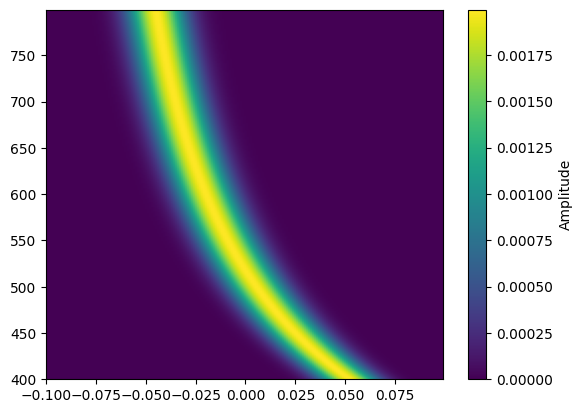

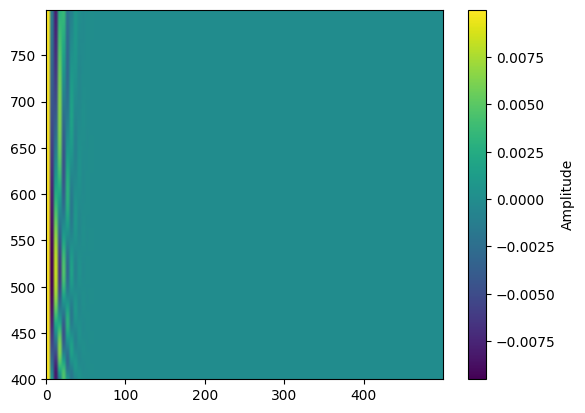

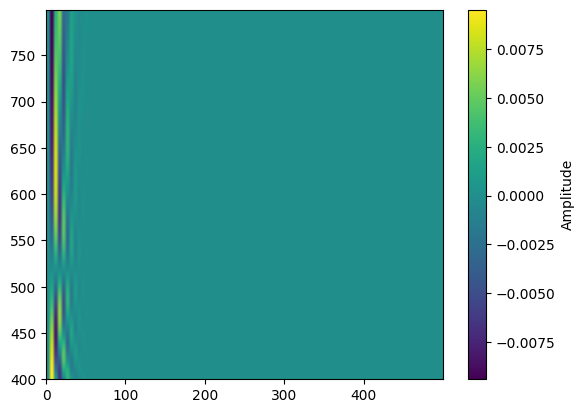

In [10]:
freq_array = jnp.arange(400,800,(800-400)/(1024/2), dtype=jnp.float32)[:, None]  # (nfreq,1), MHz
time_array = jnp.arange(-1/10,1/10,(1/10-(-1/10))/200, dtype=jnp.float32)[None, :] # (1,ntime), s

single_pulse_model = setup_model(constants_dict, freq_array, time_array)

M = single_pulse_model(params_dict)

L = time_array[0].shape[0]
dt = time_array[0][1] - time_array[0][0]
fourier_freqs = jnp.fft.rfftfreq(L, d=dt,dtype=jnp.float32)[None, :]

# M *= jnp.exp(2j *jnp.pi * fourier_freqs * 1)

M_td = 1/(L*dt)*jnp.fft.irfft(M,axis=-1)


plt.imshow(
    M_td,
    aspect='auto',
    origin='lower',
    cmap = "viridis",
    extent=[time_array[0][0], time_array[0][-1], freq_array.T[0][0], freq_array.T[0][-1]],
)

plt.colorbar(label="Amplitude")

plt.figure()

plt.imshow(
    M.real,
    aspect='auto',
    origin='lower',
    extent=[fourier_freqs[0][0], fourier_freqs[0][-1], freq_array.T[0][0], freq_array.T[0][-1]],
    cmap = "viridis"
)
plt.colorbar(label="Amplitude")

plt.figure()
plt.imshow(
    M.imag,
    aspect='auto',
    origin='lower',
    extent=[fourier_freqs[0][0], fourier_freqs[0][-1], freq_array.T[0][0], freq_array.T[0][-1]],
    cmap = "viridis"
)
plt.colorbar(label="Amplitude")


In [16]:
optimal_snr(noise_level, M_td)

Array(9.501052, dtype=float32)

In [17]:
M_td.shape[0]*M_td.shape[1]

102400

In [315]:
jax.local_device_count()

4

In [316]:
len(params_list)

1

In [317]:
initial_parameter_guess = {"alpha_0": params_dict["alpha"], "t0_0": params_dict["mean_arrival_time"], "sigma_0": params_dict["sigma"], "DM_0": params_dict["DM"], "gamma_0": params_dict["gamma"], "beta_0":params_dict["beta"]}
initial_parameter_guess

{'alpha_0': -2.0,
 't0_0': 0.08,
 'sigma_0': 0.001,
 'DM_0': 5.0,
 'gamma_0': 0.0,
 'beta_0': 0.0}

In [14]:
#running sampler
initial_parameter_guess = {"alpha_0": params_dict["alpha"], "t0_0": params_dict["mean_arrival_time"], "sigma_0": params_dict["sigma"], "DM_0": params_dict["DM"], "gamma_0": params_dict["gamma"], "beta_0":params_dict["beta"]}
kernel = NUTS(numpyro_model, dense_mass=True)#, init_strategy=init_to_value(values=initial_parameter_guess))
seed = 1
rng_key = jrand.PRNGKey(seed)
mcmc = MCMC(kernel, num_warmup=500, num_samples=500, num_chains=4, chain_method="parallel" )
mcmc.run(rng_key=rng_key, data=M, len_freq_channel_array=len_freq_channel_array, len_fourier_freq_array=len_fourier_freq_array, single_pulse_method = single_pulse_method, sigma_noise = sqrtPSD, n_pulses=1)

# samples = mcmc.get_samples()
# extra = mcmc.get_extra_fields(group_by_chain=True)

# # Create an InferenceData object
# mcmc_data = az.from_dict(
#     posterior=samples,
#     sample_stats=extra
# )

Compiling.. :   0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

Compiling.. :   0%|          | 0/1000 [00:00<?, ?it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


Running chain 1:   0%|          | 0/1000 [00:02<?, ?it/s]

Running chain 2:   0%|          | 0/1000 [00:02<?, ?it/s]


Running chain 0:   5%|▌         | 50/1000 [00:02<00:04, 224.16it/s]


Running chain 3:   5%|▌         | 50/1000 [00:03<00:09, 95.65it/s]

Running chain 2:   5%|▌         | 50/1000 [00:03<00:23, 40.63it/s]


Running chain 0:  10%|█         | 100/1000 [00:05<00:33, 27.12it/s]


Running chain 3:  15%|█▌        | 150/1000 [00:05<00:18, 44.88it/s]

Running chain 2:  10%|█         | 100/1000 [00:06<00:34, 25.88it/s]


Running chain 3:  20%|██        | 200/1000 [00:06<00:14, 55.21it/s]


Running chain 0:  15%|█▌        | 150/1000 [00:07<00:27, 31.23it/s]


Running chain 0:  20%|██        | 200/1000 [00:07<00:18, 43.45it/s]


Running chain 3:  35%|███▌      | 350/1000 [00:07<00:06, 

In [306]:
# kernel = NUTS(numpyro_model, dense_mass=True)
# seed = 1
# rng_key = jrand.PRNGKey(seed)
# mcmc = MCMC(kernel, num_warmup=500, num_samples=500, num_chains=4, chain_method="parallel" )
# mcmc.run(rng_key=rng_key, data=data_array, freq_array=freq_array, time_array=time_array, sigma_noise = 20, n_pulses=len(params_list))
# samples = mcmc.get_samples()

In [18]:
mcmc_data = az.from_numpyro(mcmc)

In [19]:
az.summary(mcmc_data, round_to=3)

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
DM_0,5.000,0.019,4.963,5.035,0.000,0.001,3205.558,1406.797,1.003
alpha_0,-2.001,0.004,-2.008,-1.994,0.000,0.000,2135.396,1648.914,1.006
beta_0,-0.002,0.161,-0.324,0.275,0.004,0.003,1596.793,1346.223,1.002
gamma_0,0.001,0.032,-0.064,0.056,0.001,0.001,2440.263,1375.300,1.004
sigma_0,0.010,0.000,0.010,0.010,0.000,0.000,1285.393,958.155,1.002
t0_0,0.080,0.000,0.080,0.080,0.000,0.000,1827.718,1488.334,1.002


In [321]:
# true_vals = {
#     "DM_0": params_dict["DM"],
#     "t0_0": params_dict["mean_arrival_time"],
#     "sigma_0": params_dict["sigma"],
#     "alpha_0": params_dict["alpha"],
#     "DM_1": params_dict_2["DM"],
#     "t0_1": params_dict_2["mean_arrival_time"],
#     "sigma_1": params_dict_2["sigma"],
#     "alpha_1": params_dict_2["alpha"],
# }

# axes = az.plot_trace(mcmc_data, var_names=["DM_0", "t0_0", "sigma_0", "alpha_0","DM_1", "t0_1", "sigma_1", "alpha_1"]);

# for i, var in enumerate(["DM_0", "t0_0", "sigma_0", "alpha_0","DM_1", "t0_1", "sigma_1", "alpha_1"]):
#     # posterior panel only
#     axes[i, 0].axvline(true_vals[var], color="black", linestyle="--", lw=2)
    
# plt.subplots_adjust(hspace=0.8)  # increase vertical spacing

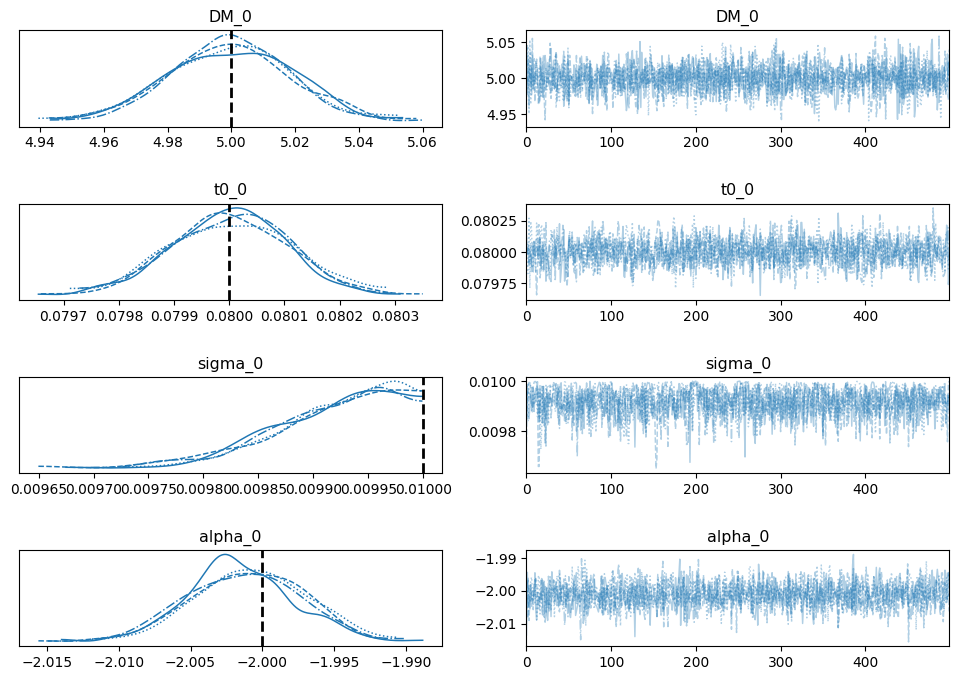

In [20]:
true_vals = {
    "DM_0": params_dict["DM"],
    "t0_0": params_dict["mean_arrival_time"],
    "sigma_0": params_dict["sigma"],
    "alpha_0": params_dict["alpha"]
}

axes = az.plot_trace(mcmc_data, var_names=["DM_0", "t0_0", "sigma_0", "alpha_0"]);

for i, var in enumerate(["DM_0", "t0_0", "sigma_0", "alpha_0"]):
    # posterior panel only
    axes[i, 0].axvline(true_vals[var], color="black", linestyle="--", lw=2)
    
plt.subplots_adjust(hspace=0.8)  # increase vertical spacing

In [21]:
jax.device_count()

4

In [22]:
os.cpu_count()

96

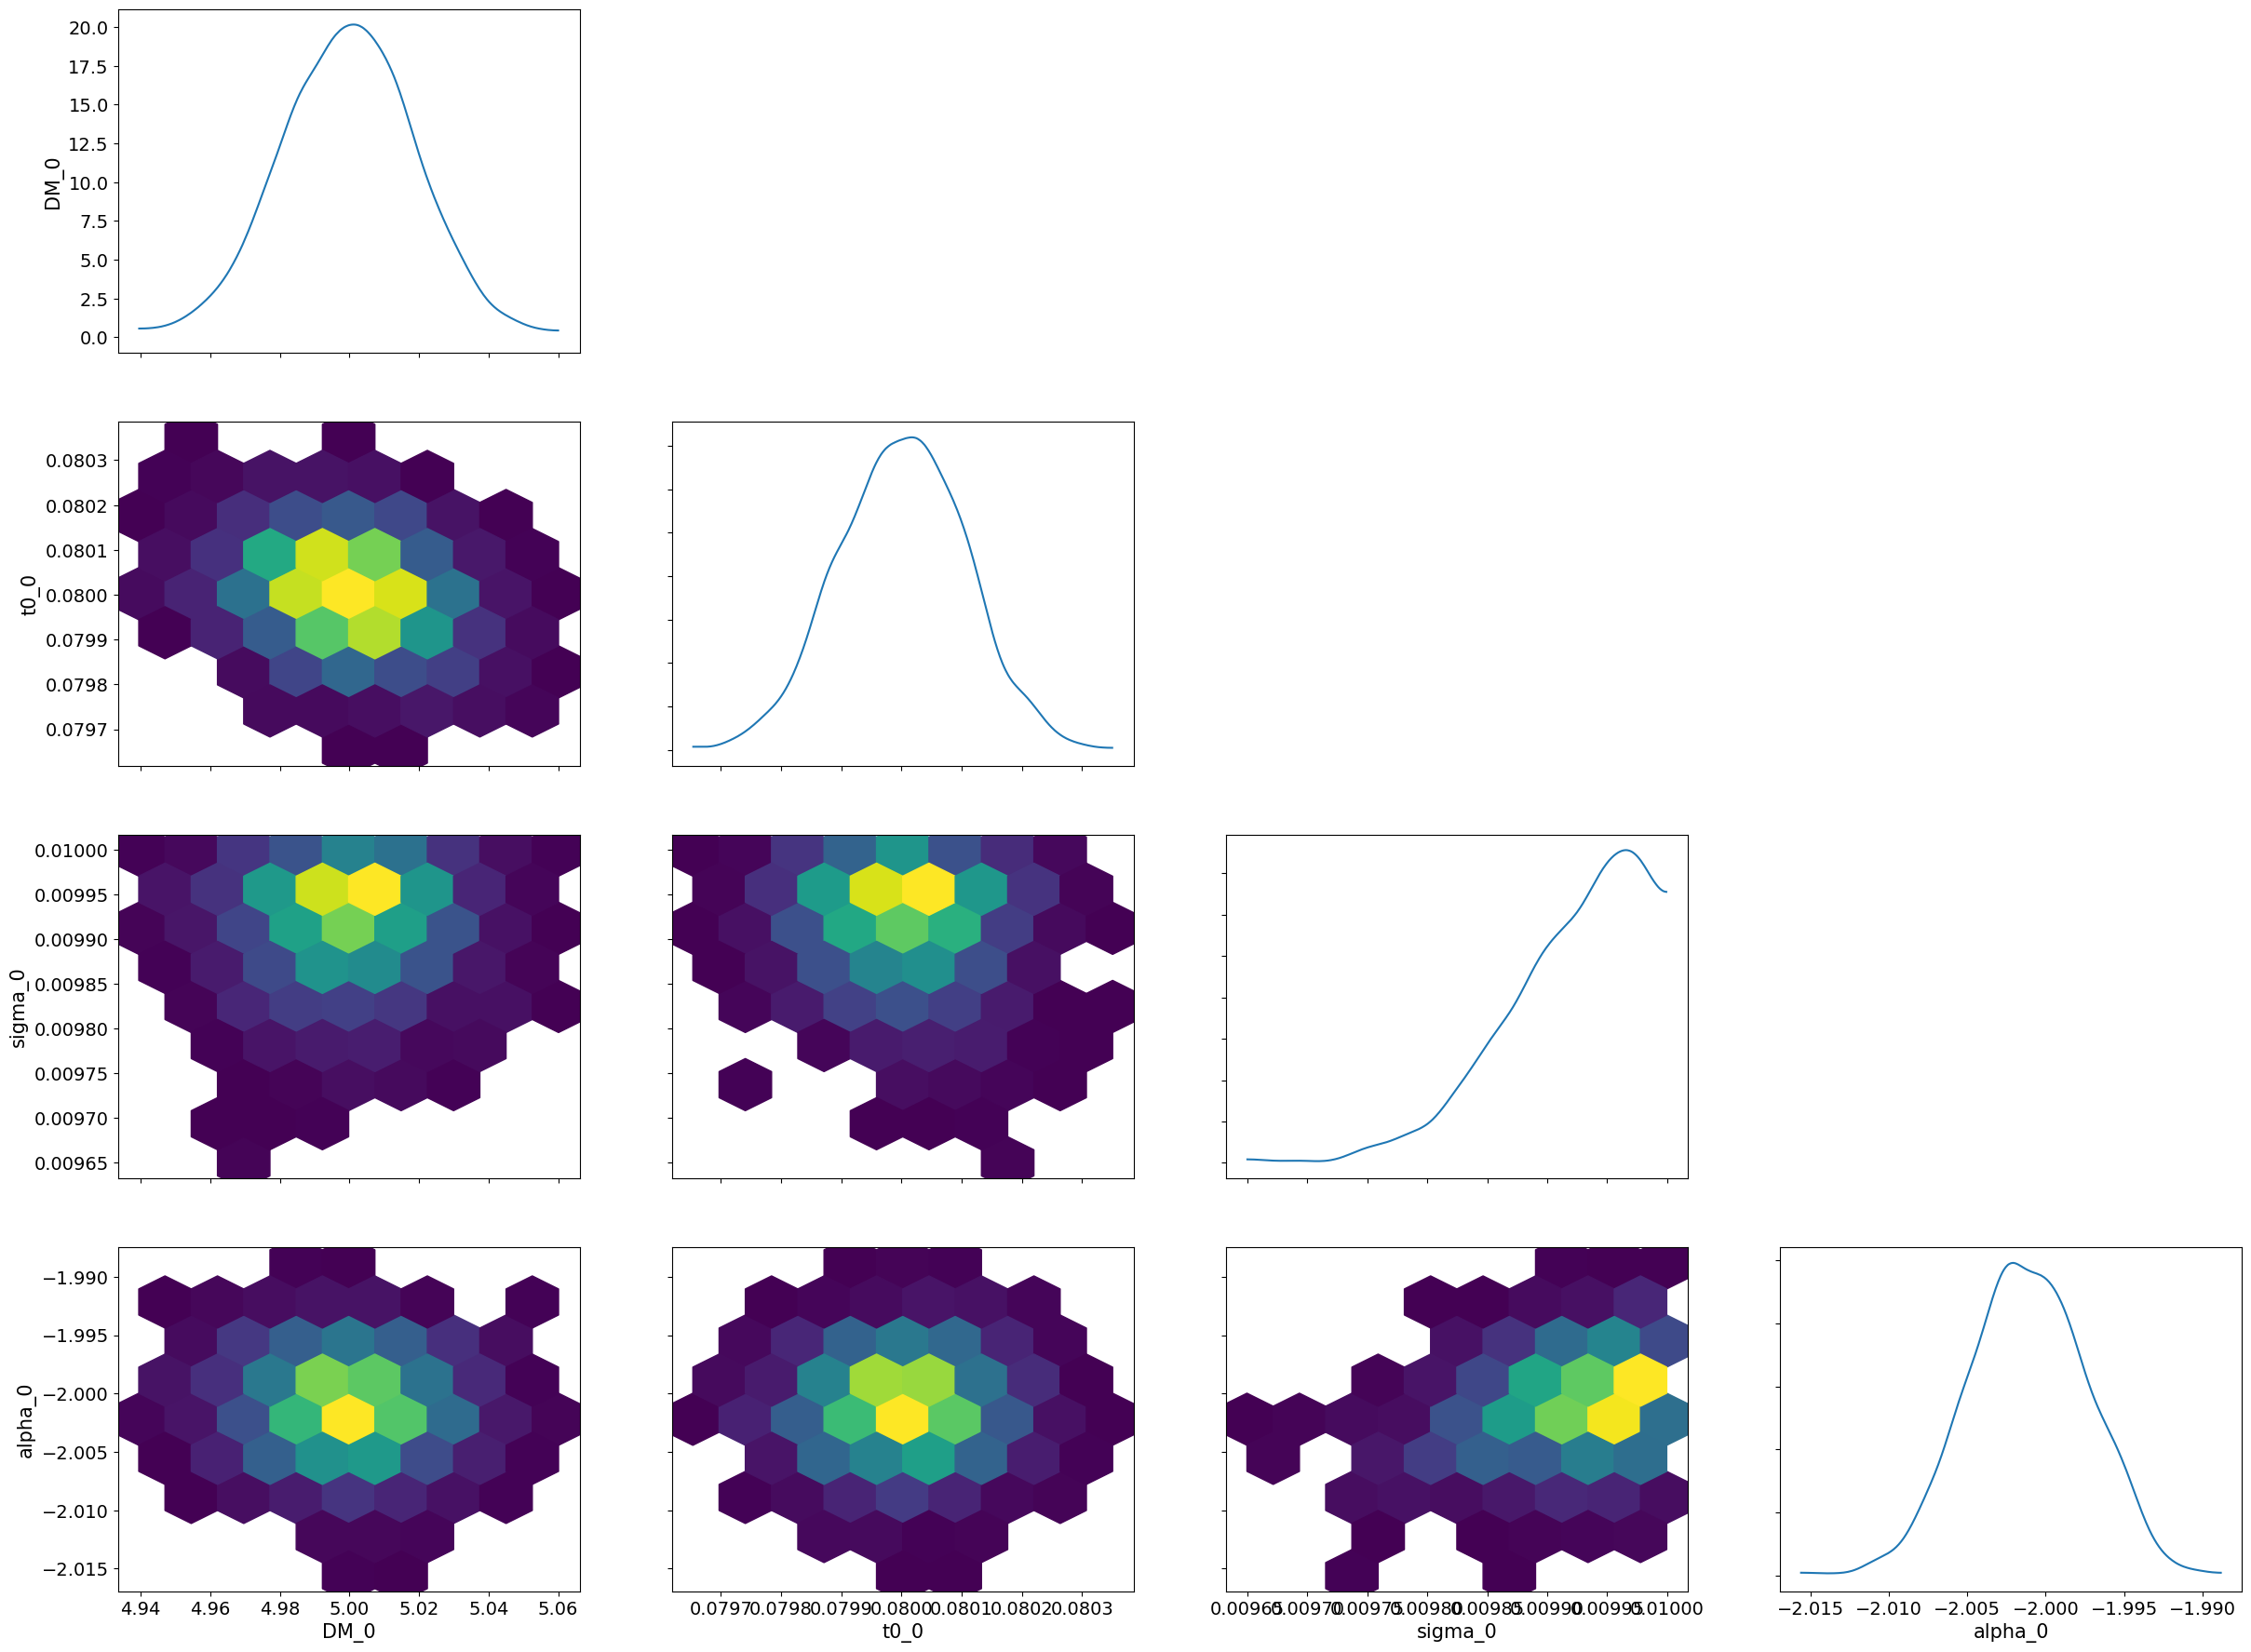

In [23]:
az.plot_pair(
    mcmc_data,
    var_names=["DM_0", "t0_0", "sigma_0", "alpha_0" ],#, "DM_1", "t0_1", "sigma_1", "alpha_1"],
    kind="hexbin",
    marginals=True
);

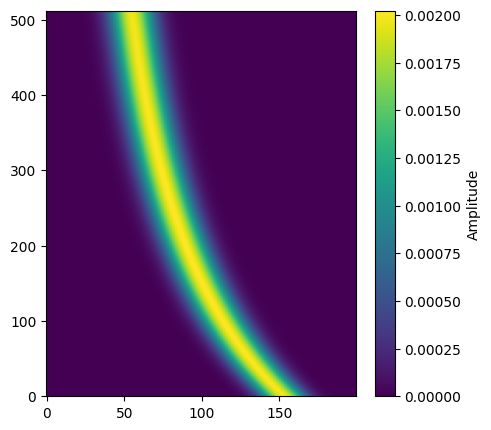

In [28]:
draw = 221
chain = 1

params_dict = {
    # Pulse and dispersion
    "DM": mcmc_data.posterior.sel(chain=chain, draw=draw).DM_0.values[()],           # pc/cm^3
    "freq_ref": 600.0,     # MHz, reference frequency near middle of band
    "tau_ref": 0.0, # mcmc_data.posterior.sel(chain=0, draw=0).tau_ref_0.values[()],#0.000, # 0.015,      # s, scatter broadening at freq_ref
    "epsilon": -2.0,        # dispersion exponent
    
    # Temporal shape
    "sigma": mcmc_data.posterior.sel(chain=chain, draw=draw).sigma_0.values[()],        # s, intrinsic width of pulse
    
    # Amplitude / spectrum
    "alpha": mcmc_data.posterior.sel(chain=chain, draw=draw).alpha_0.values[()],          # log10 global amplitude
    "gamma": mcmc_data.posterior.sel(chain=chain, draw=draw).gamma_0.values[()],         # spectral index for SED
    "beta": mcmc_data.posterior.sel(chain=chain, draw=draw).beta_0.values[()],           # running spectral index
    "delta": -4.0,          # scatter-frequency exponent
    "mean_arrival_time": mcmc_data.posterior.sel(chain=chain, draw=draw).t0_0.values[()],
    "k_DM": (2.41*1e-4)**(-1)
}

# fixed / typical values
freq_channels_ref = 600.0
# gamma = 0.0
# beta = 0.0
delta = -4.0
epsilon = -2.0
tau_ref = 0.0 #numpyro.sample(f"tau_ref_{i}", dist.Uniform(0.0, 0.01))
k_DM = (2.41*1e-4)**(-1) #pc^-1 * cm^3 * GHz^2 * s

constants_dict = {
    "freq_channels_ref": freq_channels_ref,
    "epsilon": epsilon,
    "k_DM": k_DM,
    "delta": delta,
    "tau_ref": tau_ref
}

# freq_array = jnp.arange(400,800,1, dtype=jnp.float32)[:, None]  # (nfreq,1), MHz
# time_array = jnp.arange(1,3,0.01, dtype=jnp.float32)[None, :] # (1,ntime), s
# #single_pulse_model(params_dict, freq_array, time_array)
single_pulse_method = setup_model(constants_dict, freq_array, time_array)

M = single_pulse_method(params_dict)
M_TD_sampled = 1/(L*dt) * jnp.fft.irfft(M,axis=-1)
fig = plt.figure(figsize=(5, 5))
plt.imshow(
    M_TD_sampled,
    aspect='auto',
    origin='lower',
    cmap = "viridis",
)
plt.colorbar(label="Amplitude")


In [29]:
optimal_snr(noise_level, M_TD_sampled)

Array(9.510137, dtype=float32)

In [30]:
optimal_snr(noise_level, M_td)

Array(9.501052, dtype=float32)

# Simpulse

In [24]:
import simpulse
import numpy as np
import matplotlib.pyplot as plt
import matplotlib

In [25]:
def make_plot(sp, ifreq_list, color_list, label_list):

    # check whether inputs are valid objects
    assert isinstance(sp, simpulse.single_pulse)
    assert len(ifreq_list) == len(color_list) == len(label_list)

    # given sp, get the end points of the time axis
    (plot_t0, plot_t1) = sp.get_endpoints()

    # loop over various plot types, e.g., with(out) labels
    for (plot_nt, ls, lflag) in [ (100,'-',True), (1000,':',False) ]:
        
        # make an empty array of (freq, time)
        ts = np.zeros((sp.nfreq, plot_nt))
        
        # add the pulse to the array, constrained by the end points
        sp.add_to_timestream(ts, plot_t0, plot_t1)

        # initialize empty vectors for holding plot data
        # upsample by 2 for a histogram look
        x = np.zeros(2*plot_nt)
        y = np.zeros(2*plot_nt)
        
        # assign time values
        t = np.linspace(plot_t0, plot_t1, plot_nt+1)
        x[0::2] = t[:-1]
        x[1::2] = t[1:]
        
        # looping over a set of freq channels, assign freq values to the y-axis vector
        for (ifreq, color, label) in zip(ifreq_list, color_list, label_list):
            
            #ISSUE: making the code more general, maybe ifreq need not to be an integer?
            y[0::2] = ts[ifreq,:]
            y[1::2] = ts[ifreq,:]
        
            # choose a good font
            font = {'family':'serif', 'size': 14}
            matplotlib.rc('font', **font)
            
            # plot with(out) label
            if lflag:
                plt.plot(x, y, color=color, ls=ls, label=label)
            else:
                plt.plot(x, y, color=color, ls=ls)

    plt.legend(loc='upper right').draw_frame(False)
    plt.show()
    # plt.savefig(filename)
    # plt.clf()
    # print 'wrote', filename

In [9]:
pulse_nt = 1024
nfreq = 512
freq_lo_MHz = 1000.0
freq_hi_MHz = 2000.0
dm = 10.0
sm = 4.0
intrinsic_width = 0.0
fluence = 30.0
spectral_index = 0.0
undispersed_arrival_time = 0.100

In [ ]:
simpulse.single_pulse

In [10]:
sp = simpulse.single_pulse(pulse_nt, nfreq, freq_lo_MHz, freq_hi_MHz, dm, sm, intrinsic_width, fluence, spectral_index, undispersed_arrival_time)

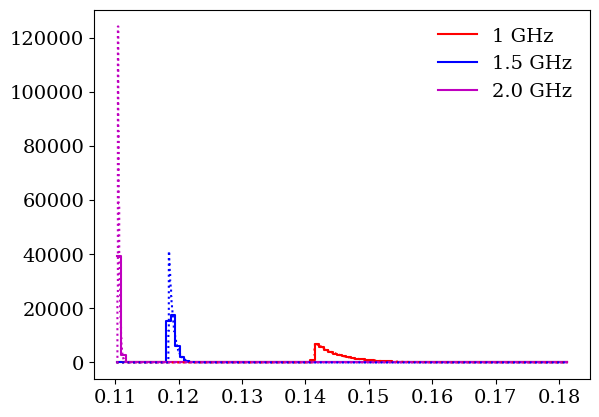

In [11]:
make_plot(sp, 
          ifreq_list = [0, 256, 511], 
          color_list = ['r', 'b', 'm'],
          label_list = [ '1 GHz', '1.5 GHz', '2.0 GHz' 

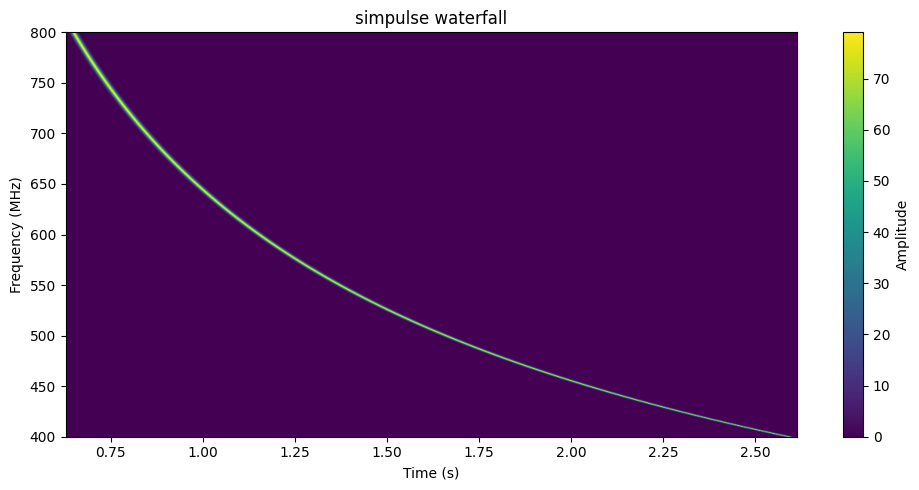

In [26]:
# ----------------------------
# 1. Define pulse parameters
# ----------------------------

pulse_nt = 1024
nfreq = 512
freq_lo_MHz = 400.0       # CHIME band
freq_hi_MHz = 800.0
dm = 100.0                # pc/cm^3
sm = 0.0                  # scattering measure
intrinsic_width = 5e-3    # s
fluence = 1.0             # arbitrary units
spectral_index = 0.0
undispersed_arrival_time = 0.  # s

# ----------------------------
# 2. Create the pulse
# ----------------------------

sp = simpulse.single_pulse(
    pulse_nt,
    nfreq,
    freq_lo_MHz,
    freq_hi_MHz,
    dm,
    sm,
    intrinsic_width,
    fluence,
    spectral_index,
    undispersed_arrival_time
)

# ----------------------------
# 3. Allocate timestream
# ----------------------------

ts = np.zeros((nfreq, pulse_nt))
plot_t0, plot_t1 = sp.get_endpoints()
sp.add_to_timestream(ts, plot_t0, plot_t1)

# ----------------------------
# 4. Compute frequency axis in MHz
# ----------------------------

freqs_MHz = np.linspace(freq_lo_MHz, freq_hi_MHz, nfreq)

# ----------------------------
# 5. Plot waterfall
# ----------------------------

plt.figure(figsize=(10,5))
plt.imshow(
    ts,
    aspect='auto',
    origin='lower',
    extent=[plot_t0, plot_t1, freqs_MHz.min(), freqs_MHz.max()]
)
plt.xlabel("Time (s)")
plt.ylabel("Frequency (MHz)")
plt.title("simpulse waterfall")
plt.colorbar(label="Amplitude")
plt.tight_layout()
plt.show()
